# AP02 – Data Preparation Cheat Sheet
## Inhaltsverzeichnis

<div style="line-height: 1;">
<strong>
1. Libraries & Settings<br>
2. Importing Data<br>
3. Extract information from raw data using regular expressions (regex)<br>
4. Get data types<br>
5. Count number of rows and columns in the data frame (Datenüberblick)<br>
6. Missing Values: Imputation<br>
7. Fehlende Werte gezielt untersuchen und entfernen<br>
8. Count and remove missing values<br>
9. Duplikate zählen, untersuchen und entfernen<br>
10. Count and remove duplicated values<br>
11. Use string manipulation methods to create additional variables<br>
12. Neue Variablen erstellen und berechnen
</strong>
</div>

## Libraries & Settings

In [1]:
# Libraries
import os
import re
import time
import fnmatch
import numpy as np
import pandas as pd
import seaborn as sns
from datetime import datetime
import matplotlib.pyplot as plt

# Ignore warnings
import warnings
warnings.filterwarnings("ignore")

# Get current working directory
print(os.getcwd())

/workspaces/DS_HS2026_LNW/DS_HS2026_LNW_I_Examples/AP02/AP02 V4 Data Preparation


## Importing Data
#### df_dpspick_apartments, df_dpspick_autoscout und df_dpspick_smartphone

In [2]:
#Falls du Dateien nicht findest (Speicherorte), diesen Code ausführen und den Output anschauen!
import os                               #Zugriff auf Ordnerinformationen
print("Arbeitsordner:", os.getcwd())    #Ordner anzeigen, von dem der relative Dateipfad ausgeht
print("Dateien:", os.listdir())         #Dateinamen im Arbeitsordner anzeigen

Arbeitsordner: /workspaces/DS_HS2026_LNW/DS_HS2026_LNW_I_Examples/AP02/AP02 V4 Data Preparation
Dateien: ['apartments_data_zuerich.csv', 'apartments_data_geocoded.csv', 'AP02 V4.1 DP Aufgaben.ipynb', 'AP02 V4 DP Spick 2.ipynb', 'autoscout24_data.csv', 'autoscout24_data_geocoded.csv', 'AP02 V4 DP Spick 1.ipynb', 'municipality_data.xlsx', 'AP02 V4.2 DP Aufgaben.ipynb', 'AP02 V4.1 DP Lösung.ipynb', 'AP02 V4.2 DP Lösung.ipynb']


In [3]:
# Read the data to a pandas data frame
df_dpspick_apartments = pd.read_csv('./apartments_data_zuerich.csv',            #CSV aus dem Arbeitsordner einlesen und als df speichern
                 sep=',',                                                       #Komma als Trennzeichen verwenden
                 encoding='utf-8')                                              #Datei mit UTF-8-Zeichenkodierung lesen

# Show first records of data frame
df_dpspick_apartments.head()                                                    #Erste fünf Zeilen der Tabelle anzeigen


#Dateien einlesen: car data
# Import data from csv to pandas dataframe named 'df'
df_dpspick_autoscout = pd.read_csv('./autoscout24_data.csv',                    #CSV aus dem Arbeitsordner einlesen und als df speichern
                 sep=";",                                                       #Komma als Trennzeichen verwenden
                 encoding='utf-8')                                              #Datei mit UTF-8-Zeichenkodierung lesen

# Change the column names to lowercase
df_dpspick_autoscout.columns = df_dpspick_autoscout.columns.str.lower()         #Alle Spaltennamen in Kleinbuchstaben umwandeln

# Display the first 5 rows of the dataframe
df_dpspick_autoscout.head()                                                     #Erste fünf Zeilen der Tabelle anzeigen


#Dateien einlesen: smartphone data
# Import data from csv to pandas dataframe named 'df_clean'
df_dpspick_smartphone = pd.read_csv('../AP02 Mock Exam/smartphones_clean.csv')  #CSV aus dem Arbeitsordner einlesen und als df_clean speichern

# Show dimensions and first rows
print('Number of rows and columns:', df_dpspick_smartphone.shape)               #Anzahl Zeilen und Spalten als (Zeilen, Spalten) anzeigen
df_dpspick_smartphone.head()                                                    #Erste fünf Zeilen der Tabelle anzeigen

Number of rows and columns: (142, 9)


,product_id,brand,model,storage_gb,color,screen_inch,battery_mah,price_chf,availability
0,PM-10001,Xiaomi,Redmi Note 14 Pro 5G,256,Midnight Black,6.67,5110,299.0,Sofort lieferbar
1,PM-10002,OnePlus,OnePlus 13,256,Arctic Dawn,6.82,6000,899.0,Lieferbar in 2–5 Tagen
2,PM-10003,Google,Pixel 10 Pro,512,Obsidian,6.30,4870,1249.0,Sofort lieferbar
3,PM-10004,Samsung,Galaxy A36 5G,128,Awesome Lavender,6.70,5000,339.0,Sofort lieferbar
4,PM-10005,Samsung,Galaxy Z Fold7,1024,Jetblack,8.00,4400,NaN,Vorbestellung


### Anzahl Zeilen und Spalten einer Tabelle anzeigen

Zeigt, wie viele Datensätze und Merkmale die Tabelle enthält
- Zeilen = Datensätze, bspw. einzelne Velos
- Spalten = Merkmale, bspw. Marke, Modell und Preis
- df.shape liefert beide Anzahlen als (Zeilen, Spalten)
- df.shape[0] liefert nur die Zeilenanzahl
- df.shape[1] liefert nur die Spaltenanzahl

In [4]:
print("Dimension:", df_dpspick_apartments.shape)                                #Anzahl Zeilen und Spalten als (Zeilen, Spalten)
print("Anzahl Zeilen:", df_dpspick_apartments.shape[0])                         #Anzahl Datensätze anzeigen  
print("Anzahl Spalten:", df_dpspick_apartments.shape[1])                        #Anzahl Merkmale anzeigen

#0 und 1 bleiben gleich: Sie wählen die Zeilenanzahl bzw. Spaltenanzahl aus
#Gezählt werden alle vorhandenen Zeilen und Spalten, auch bei fehlenden Werten oder Duplikaten

Dimension: (1008, 7)
Anzahl Zeilen: 1008
Anzahl Spalten: 7


### Vorhandene Spaltennamen anzeigen

Zeigt die exakten Namen aller Spalten einer Tabelle als Liste an; damit kannst du prüfen, welche Spalten vorhanden sind und wie sie geschrieben werden

Gross-/Kleinschreibung beachten: `Price_Raw`, `price_raw` und `price` sind unterschiedliche Spaltennamen
Ein `KeyError` kann bedeuten, dass die angegebene Spalte fehlt oder anders geschrieben ist

In [5]:
print(df_dpspick_autoscout.columns.tolist())            #Vorhandene Spalten von df_autoscout anzeigen

display(df_dpspick_autoscout)                           #Gesamten Dataframe anzeigen

['url_short', 'offer_id', 'scrape_dt', 'type', 'price_raw', 'hp_raw', 'init_regist', 'mileage_raw', 'fuel_type', 'transmission', 'dealer_name', 'dealer_plz', 'dealer_city', 'dealer_street_house_nr', 'dealer_telnr', 'init_regist_my', 'init_regist_month', 'init_regist_year', 'init_regist_dt']


,url_short,offer_id,scrape_dt,type,price_raw,hp_raw,init_regist,mileage_raw,fuel_type,transmission,dealer_name,dealer_plz,dealer_city,dealer_street_house_nr,dealer_telnr,init_regist_my,init_regist_month,init_regist_year,init_regist_dt
0,https://www.autoscout24.ch/7324420,7324420,2020_03_17 07:34:45,AUDI A5 Sportback 3.0 TDI quattro S-tronic (Li...,CHF 22'500.–,245 PS,10.2014,75'000 km,Diesel,Automatisiertes Schaltgetriebe,***confidential***,8488,Turbenthal,Mettlenstrasse 3,***confidential***,10.2014,10.0,2014.0,2014-10
1,https://www.autoscout24.ch/7512768,7512768,2020_03_17 07:34:55,MERCEDES-BENZ SLK 200 7G-Tronic (Cabriolet),CHF 23'749.–,184 PS,6.2013,46'655 km,Benzin,Automat sequentiell,***confidential***,3186,Düdingen,Brugerastrasse 60,***confidential***,6.2013,6.0,2013.0,2013-06
2,https://www.autoscout24.ch/7512034,7512034,2020_03_17 07:35:03,MERCEDES-BENZ C 350 Avantgarde 4Matic 7G-Troni...,CHF 18'500.–,306 PS,6.2011,138'955 km,Benzin,Automat sequentiell,***confidential***,1262,Eysins,1262 Eysins,***confidential***,6.2011,6.0,2011.0,2011-06
3,https://www.autoscout24.ch/7512728,7512728,2020_03_17 07:35:06,MERCEDES-BENZ A 45 AMG 4Matic Speedshift 7G-DC...,CHF 36'000.–,360 PS,8.2015,43'000 km,Benzin,Automatisiertes Schaltgetriebe,***confidential***,4314,Zeiningen,Am Stutz 21,***confidential***,8.2015,8.0,2015.0,2015-08
4,https://www.autoscout24.ch/7490242,7490242,2020_03_17 07:35:16,AUDI A5 Sportback 2.0 TFSI Sport quattro S-tro...,CHF 48'500.–,252 PS,9.2018,43'300 km,Benzin,Automatisiertes Schaltgetriebe,***confidential***,3250,Lyss,3250 Lyss,***confidential***,9.2018,9.0,2018.0,2018-09
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3975,https://www.autoscout24.ch/7137137,7137137,2020_03_17 06:03:15,FERRARI F360 Spider (Cabriolet),CHF 58'400.–,400 PS,2.2002,78'000 km,Benzin,Automatisiertes Schaltgetriebe,***confidential***,8852,Altendorf,8852 Altendorf,***confidential***,2.2002,2.0,2002.0,2002-02
3976,https://www.autoscout24.ch/6758841,6758841,2020_03_17 07:15:07,MERCEDES-BENZ SL 500 560 SL (Cabriolet),CHF 15'900.–,232 PS,1.1987,315'000 km,Benzin,Automatik-Getriebe,***confidential***,9444,DIEPOLDSAU,WERKSTRASSE 10 1,***confidential***,1.1987,1.0,1987.0,1987-01
3977,https://www.autoscout24.ch/7461330,7461330,2020_03_17 07:18:31,MERCEDES-BENZ CL 63 AMG 7G-Tronic (Coupé),CHF 42'000.–,525 PS,8.2007,85'000 km,Benzin,Automat sequentiell,***confidential***,8953,Dietikon,8953 Dietikon,***confidential***,8.2007,8.0,2007.0,2007-08
3978,https://www.autoscout24.ch/7005403,7005403,2020_03_17 07:30:54,BMW 328i Cabrio (Cabriolet),CHF 9'980.–,193 PS,8.1995,188'920 km,Benzin,Schaltgetriebe manuell,***confidential***,2543,Lengnau,Mühleweg 8,***confidential***,8.1995,8.0,1995.0,1995-08


## Extract information from raw data using regular expressions (regex)
### Voraussetzung: import re

##### Wichtige Stolpersteine

- `r"(\d+)\s*Zimmer"` findet bei `"3,5 Zimmer"` ebenfalls einen Treffer, allerdings nur `"5"`. Die einfache Ganzzahlvariante prüft nicht, ob davor ein Komma oder Punkt steht. Für gemischte Zahlenformate ist `r"(\d+(?:[.,]\d+)?)\s*Zimmer"` geeigneter
- Dasselbe gilt für `r"(\d+)\s*m²"`: Bei `"49,5 m²"` wird nur `"5"` erfasst; für Dezimalzahlen das erweiterte Zahlenmuster verwenden
- `''.join(re.findall(r"\d+", text))` nur verwenden, wenn der Text genau eine zusammengehörige Zahl enthält. Bei `"75'000 km, 245 PS"` würden sonst Kilometer und PS zu `"75000245"` verschmelzen
- Die Muster prüfen nicht automatisch das vollständige Zahlenformat. Das flexible CHF-Muster kann bei `"CHF 1249.999"` bspw. nur `"1249.99"` erfassen

#### Regex-Muster: Varianten und Bedeutung

| Regex-Muster | Bedeutung |
|---|---|
| `r"(\d+)\s*Zimmer"` | sucht eine ganze Zahl vor „Zimmer“, bspw. `"3 Zimmer"` → `"3"` |
| `r"(\d+,\d+)\s*Zimmer"` | sucht eine Dezimalzahl mit Komma vor „Zimmer“, bspw. `"3,5 Zimmer"` → `"3,5"` |
| `r"(\d+,\d+\|\d+)\s*Zimmer"` | sucht eine Dezimalzahl mit Komma ODER eine ganze Zahl vor „Zimmer“, bspw. `"3,5 Zimmer"` → `"3,5"` oder `"3 Zimmer"` → `"3"` |
| `r"(\d+(?:[.,]\d+)?)\s*Zimmer"` | sucht eine ganze Zahl oder Dezimalzahl mit Komma ODER Punkt vor „Zimmer“, bspw. `"3 Zimmer"` → `"3"`, `"3,5 Zimmer"` → `"3,5"` oder `"3.5 Zimmer"` → `"3.5"` |
| `r"(\d+(?:[.,]\d+)?)\s*kg"` | verwendet dasselbe Zahlenmuster für Gewichte vor „kg“, bspw. `"12,8 kg"` → `"12,8"` |
| `r"\d+"` | sucht im Text nach einer oder mehreren direkt aufeinanderfolgenden Ziffern und gibt mit `re.findall()` jede gefundene Ziffernfolge als eigenen Treffer zurück. Andere Zeichen unterbrechen die Folge: Bei `"75'000 km"` entstehen deshalb zwei Treffer `["75", "000"]`, die erst durch `''.join(d1)` zu `"75000"` verbunden werden; dasselbe Muster funktioniert für PS-Angaben wie `"245 PS"` → `["245"]` |
| `r"(\d+)\s*m²"` | sucht eine ganze Zahl vor „m²“ und erfasst nur die Zahl, bspw. `"3 Zimmer, 49 m², CHF 1441"` → `"49"`; zwischen Zahl und Einheit darf beliebig viel Leerraum stehen, auch keiner |
| `r"(\d+(?:[.,]\d+)?)\s*m²"` | erfasst auch Flächen mit Dezimalstellen, bspw. `"49,5 m²"` → `"49,5"` oder `"49.5 m²"` → `"49.5"` |
| `r"(\d+(?:[.,]\d+)?)\s*%"` | erfasst Prozentangaben, bspw. `"12,5 %"` → `"12,5"` oder `"12.5%"` → `"12.5"` |

In [6]:
#Ganze Zimmerzahl extrahieren und als Ganzzahl speichern
rooms = []
for i in df_dpspick_apartments['rooms_area_price_raw']:                         #ANPASSEN: DataFrame und Rohtextspalte
    d1 = re.findall(r"(\d+)\s*Zimmer", str(i))                                  #"3 Zimmer" => ["3"]; ANPASSEN: Einheit Zimmer
    try:
        d2 = d1[0].strip()
    except IndexError:
        d2 = None
    rooms.append(d2)
#Extrahierte Werte als neue Spalte speichern
df_dpspick_apartments['rooms_int'] = pd.Series(
    rooms, index=df_dpspick_apartments.index, dtype="Int64"
)                                                                               
#Rohtext und extrahierte Werte anzeigen
display(df_dpspick_apartments[['rooms_area_price_raw', 'rooms_int']].head())    


#Zimmerzahl mit Dezimalkomma extrahieren und numerisch speichern
rooms = []
for i in df_dpspick_apartments['rooms_area_price_raw']:                         #ANPASSEN: DataFrame und Rohtextspalte
    d1 = re.findall(r"(\d+,\d+)\s*Zimmer", str(i))                              #"3,5 Zimmer" => ["3,5"]; ANPASSEN: Einheit Zimmer
    try:
        d2 = d1[0].strip().replace(',', '.')                                  
    except IndexError:
        d2 = None
    rooms.append(d2)
#Extrahierte Werte als neue Spalte speichern
df_dpspick_apartments['rooms_comma'] = pd.Series(
    rooms, index=df_dpspick_apartments.index, dtype="float64"
)                                                                            
#Rohtext und extrahierte Werte anzeigen
display(df_dpspick_apartments[['rooms_area_price_raw', 'rooms_comma']].head())  #ANPASSEN: DataFrame, Rohtextspalte und Zielspalte


#Zimmerzahl mit Dezimalkomma ODER ganze Zimmerzahl extrahieren
rooms = []
for i in df_dpspick_apartments['rooms_area_price_raw']:                         #ANPASSEN: DataFrame und Rohtextspalte
    d1 = re.findall(r"(\d+,\d+|\d+)\s*Zimmer", str(i))                          #"3,5 Zimmer" => ["3,5"]; "3 Zimmer" => ["3"]; ANPASSEN: Einheit
    try:
        d2 = d1[0].strip().replace(',', '.')                                  
    except IndexError:
        d2 = None
    rooms.append(d2)
#Extrahierte Werte als neue Spalte speichern
df_dpspick_apartments['rooms'] = pd.Series(
    rooms, index=df_dpspick_apartments.index, dtype="float64"
)                                                                            
#Rohtext und extrahierte Werte anzeigen
display(df_dpspick_apartments[['rooms_area_price_raw', 'rooms']].head())        #ANPASSEN: DataFrame, Rohtextspalte und Zielspalte


#Zimmerzahl mit Komma, Punkt oder ohne Dezimalstellen extrahieren
rooms = []
for i in df_dpspick_apartments['rooms_area_price_raw']:                         #ANPASSEN: DataFrame und Rohtextspalte
    d1 = re.findall(r"(\d+(?:[.,]\d+)?)\s*Zimmer", str(i))                      #"3.5 Zimmer" => ["3.5"]; "3,5 Zimmer" => ["3,5"]; ANPASSEN: Einheit
    try:
        d2 = d1[0].strip().replace(',', '.')                                    
    except IndexError:
        d2 = None
    rooms.append(d2)
#Extrahierte Werte als neue Spalte speichern
df_dpspick_apartments['rooms'] = pd.Series(
    rooms, index=df_dpspick_apartments.index, dtype="float64"
)                                                                            
#Rohtext und extrahierte Werte anzeigen
display(df_dpspick_apartments[['rooms_area_price_raw', 'rooms']].head())        #ANPASSEN: DataFrame, Rohtextspalte und Zielspalte


#Gewichte aus Beispieltexten extrahieren
df_weights = pd.DataFrame({'weight_raw': ['12,8 kg', '5 kg', 'keine Angabe']})  #ANPASSEN: Bei echten Daten den bereits eingelesenen DataFrame verwenden
weights = []
for i in df_weights['weight_raw']:                                              #ANPASSEN: DataFrame und Rohtextspalte
    d1 = re.findall(r"(\d+(?:[.,]\d+)?)\s*kg", str(i))                          #"12,8 kg" => ["12,8"]; ANPASSEN: Einheit kg
    try:
        d2 = d1[0].strip().replace(',', '.')                                    
    except IndexError:
        d2 = None
    weights.append(d2)
#Extrahierte Werte als neue Spalte speichern
df_weights['weight_kg'] = pd.Series(
    weights, index=df_weights.index, dtype="float64"
)                                                                               
#Rohtext und extrahierte Werte anzeigen
display(df_weights[['weight_raw', 'weight_kg']].head())                         #ANPASSEN: DataFrame, Rohtextspalte und Zielspalte


#Ziffernfolgen aus Kilometerangaben extrahieren und zu einer Zahl verbinden
mileage = []
for i in df_dpspick_autoscout['mileage_raw']:                                   #ANPASSEN: DataFrame und Rohtextspalte
    d1 = re.findall(r"\d+", str(i))                                             #"75'000 km" => ["75", "000"]
    d2 = ''.join(d1) if d1 else None                                            #["75", "000"] => "75000"; kein Treffer => None
    mileage.append(d2)
#Extrahierte Werte als neue Spalte speichern
df_dpspick_autoscout['mileage_numeric'] = pd.Series(
    mileage, index=df_dpspick_autoscout.index, dtype="Int64"
)                                                                            
#Rohtext und extrahierte Werte anzeigen
display(df_dpspick_autoscout[['mileage_raw', 'mileage_numeric']].head())        #ANPASSEN: DataFrame, Rohtextspalte und Zielspalte


#Ganze Fläche vor m² extrahieren und numerisch speichern
area = []
for i in df_dpspick_apartments['rooms_area_price_raw']:                         #ANPASSEN: DataFrame und Rohtextspalte
    d1 = re.findall(r"(\d+)\s*m²", str(i))                                      #"3 Zimmer, 49 m², CHF 1441" => ["49"]; ANPASSEN: Einheit m²
    try:
        d2 = d1[0].strip()
    except IndexError:
        d2 = None
    area.append(d2)
#Extrahierte Werte als neue Spalte speichern
df_dpspick_apartments['area_m2'] = pd.Series(
    area, index=df_dpspick_apartments.index, dtype="Int64"
)                                                                            
#Rohtext und extrahierte Werte anzeigen
display(df_dpspick_apartments[['rooms_area_price_raw', 'area_m2']].head())      #ANPASSEN: DataFrame, Rohtextspalte und Zielspalte


#Fläche mit Komma, Punkt oder ohne Dezimalstellen extrahieren
area = []
for i in df_dpspick_apartments['rooms_area_price_raw']:                        #ANPASSEN: DataFrame und Rohtextspalte
    d1 = re.findall(r"(\d+(?:[.,]\d+)?)\s*m²", str(i))                         #"49,5 m²" => ["49,5"]; ANPASSEN: Einheit m²
    try:
        d2 = d1[0].strip().replace(',', '.')                                    #"49,5" => "49.5"
    except IndexError:
        d2 = None
    area.append(d2)
#Extrahierte Werte als neue Spalte speichern
df_dpspick_apartments['area_m2'] = pd.Series(
    area, index=df_dpspick_apartments.index, dtype="float64"
)                                                                               
#Rohtext und extrahierte Werte anzeigen
display(df_dpspick_apartments[['rooms_area_price_raw', 'area_m2']].head())      #ANPASSEN: DataFrame, Rohtextspalte und Zielspalte


#Prozentzahlen aus Beispieltexten extrahieren
df_percentages = pd.DataFrame({'percentage_raw': ['12,5 %', '20%', 'keine Angabe']})  
                                                                                #ANPASSEN: Bei echten Daten den bereits eingelesenen DataFrame verwenden

percentages = []
for i in df_percentages['percentage_raw']:                                      #ANPASSEN: DataFrame und Rohtextspalte
    d1 = re.findall(r"(\d+(?:[.,]\d+)?)\s*%", str(i))                           #"12,5 %" => ["12,5"]; ANPASSEN: Einheit %
    try:
        d2 = d1[0].strip().replace(',', '.')                                    
    except IndexError:
        d2 = None
    percentages.append(d2)

#Extrahierte Werte als neue Spalte speichern
df_percentages['percentage'] = pd.Series(
    percentages, index=df_percentages.index, dtype="float64"
)                                                                               #ANPASSEN: DataFrame, Index und Zielspalte; "12.5" => 12.5, None => NaN

#Rohtext und extrahierte Werte anzeigen
display(df_percentages[['percentage_raw', 'percentage']].head())                #ANPASSEN: DataFrame, Rohtextspalte und Zielspalte

,rooms_area_price_raw,rooms_int
0,"3 Zimmer, 49 m², CHF 1441.—",3
1,"3,5 Zimmer, 65 m², CHF 1850.—",5
2,"19 m², CHF 2686.—",<NA>
3,"2 Zimmer, 54 m², CHF 4853.—",2
4,"2 Zimmer, 49 m², CHF 4335.—",2


,rooms_area_price_raw,rooms_comma
0,"3 Zimmer, 49 m², CHF 1441.—",NaN
1,"3,5 Zimmer, 65 m², CHF 1850.—",3.5
2,"19 m², CHF 2686.—",NaN
3,"2 Zimmer, 54 m², CHF 4853.—",NaN
4,"2 Zimmer, 49 m², CHF 4335.—",NaN


,rooms_area_price_raw,rooms
0,"3 Zimmer, 49 m², CHF 1441.—",3.0
1,"3,5 Zimmer, 65 m², CHF 1850.—",3.5
2,"19 m², CHF 2686.—",NaN
3,"2 Zimmer, 54 m², CHF 4853.—",2.0
4,"2 Zimmer, 49 m², CHF 4335.—",2.0


,rooms_area_price_raw,rooms
0,"3 Zimmer, 49 m², CHF 1441.—",3.0
1,"3,5 Zimmer, 65 m², CHF 1850.—",3.5
2,"19 m², CHF 2686.—",NaN
3,"2 Zimmer, 54 m², CHF 4853.—",2.0
4,"2 Zimmer, 49 m², CHF 4335.—",2.0


,weight_raw,weight_kg
0,"12,8 kg",12.8
1,5 kg,5.0
2,keine Angabe,NaN


,mileage_raw,mileage_numeric
0,75'000 km,75000
1,46'655 km,46655
2,138'955 km,138955
3,43'000 km,43000
4,43'300 km,43300


,rooms_area_price_raw,area_m2
0,"3 Zimmer, 49 m², CHF 1441.—",49
1,"3,5 Zimmer, 65 m², CHF 1850.—",65
2,"19 m², CHF 2686.—",19
3,"2 Zimmer, 54 m², CHF 4853.—",54
4,"2 Zimmer, 49 m², CHF 4335.—",49


,rooms_area_price_raw,area_m2
0,"3 Zimmer, 49 m², CHF 1441.—",49.0
1,"3,5 Zimmer, 65 m², CHF 1850.—",65.0
2,"19 m², CHF 2686.—",19.0
3,"2 Zimmer, 54 m², CHF 4853.—",54.0
4,"2 Zimmer, 49 m², CHF 4335.—",49.0


,percentage_raw,percentage
0,"12,5 %",12.5
1,20%,20.0
2,keine Angabe,NaN


##### Ganze Beträge ohne Tausendertrennzeichen

| Regex-Muster | Bedeutung |
|---|---|
| `r"CHF\s*(\d+)\.—"` | sucht eine ganze Zahl mit Punkt und langem Gedankenstrich `—`, bspw. `"CHF 1441.—"` → `"1441"` |
| `r"CHF\s*(\d+)\.–"` | sucht eine ganze Zahl mit Punkt und kurzem Gedankenstrich `–`, bspw. `"CHF 1441.–"` → `"1441"` |
| `r"CHF\s*(\d+)\.-"` | sucht eine ganze Zahl mit Punkt und Bindestrich `-`, bspw. `"CHF 1441.-"` → `"1441"` |
| `r"CHF\s*(\d+)\.[—–-]"` | erlaubt alle drei Strichvarianten nach dem Punkt, bspw. `"CHF 1441.—"`, `"CHF 1441.–"` oder `"CHF 1441.-"` → `"1441"`; `[—–-]` bedeutet eines dieser drei Zeichen |

In [7]:
#Ganzen CHF-Betrag mit Punkt und langem Gedankenstrich extrahieren
price = []
for i in df_dpspick_apartments['price_raw']:                                    #ANPASSEN: DataFrame und Rohtextspalte
    d1 = re.findall(r"CHF\s*(\d+)\.—", str(i))                                  #"CHF 1441.—" => ["1441"]; ANPASSEN: Währung und Strichvariante
    try:
        d2 = d1[0].strip()
    except IndexError:
        d2 = None
    price.append(d2)
#Extrahierte Werte als neue Spalte speichern
df_dpspick_apartments['price_em_dash'] = pd.Series(
    price, index=df_dpspick_apartments.index, dtype="Int64"
)                                                                               
#Rohtext und extrahierte Werte anzeigen
display(df_dpspick_apartments[['price_raw', 'price_em_dash']].head())           #ANPASSEN: DataFrame, Rohtextspalte und Zielspalte


#Ganzen CHF-Betrag mit Punkt und kurzem Gedankenstrich extrahieren
price = []
for i in df_dpspick_apartments['price_raw']:                                    #ANPASSEN: DataFrame und Rohtextspalte
    d1 = re.findall(r"CHF\s*(\d+)\.–", str(i))                                  #"CHF 1441.–" => ["1441"]; ANPASSEN: Währung und Strichvariante
    try:
        d2 = d1[0].strip()
    except IndexError:
        d2 = None
    price.append(d2)
#Extrahierte Werte als neue Spalte speichern
df_dpspick_apartments['price_en_dash'] = pd.Series(
    price, index=df_dpspick_apartments.index, dtype="Int64"
)                                                                               
#Rohtext und extrahierte Werte anzeigen
display(df_dpspick_apartments[['price_raw', 'price_en_dash']].head())           #ANPASSEN: DataFrame, Rohtextspalte und Zielspalte


#Ganzen CHF-Betrag mit Punkt und Bindestrich extrahieren
price = []
for i in df_dpspick_apartments['price_raw']:                                    #ANPASSEN: DataFrame und Rohtextspalte
    d1 = re.findall(r"CHF\s*(\d+)\.-", str(i))                                  #"CHF 1441.-" => ["1441"]; ANPASSEN: Währung und Strichvariante
    try:
        d2 = d1[0].strip()
    except IndexError:
        d2 = None
    price.append(d2)
#Extrahierte Werte als neue Spalte speichern
df_dpspick_apartments['price_hyphen'] = pd.Series(
    price, index=df_dpspick_apartments.index, dtype="Int64"
)                                                                               
#Rohtext und extrahierte Werte anzeigen
display(df_dpspick_apartments[['price_raw', 'price_hyphen']].head())            #ANPASSEN: DataFrame, Rohtextspalte und Zielspalte


#Ganzen CHF-Betrag mit einer der drei Strichvarianten extrahieren
price = []
for i in df_dpspick_apartments['price_raw']:                                    #ANPASSEN: DataFrame und Rohtextspalte
    d1 = re.findall(r"CHF\s*(\d+)\.[—–-]", str(i))                              #"CHF 1441.—", "CHF 1441.–" oder "CHF 1441.-" => ["1441"]; ANPASSEN: Währung
    try:
        d2 = d1[0].strip()
    except IndexError:
        d2 = None
    price.append(d2)

#Extrahierte Werte als neue Spalte speichern
df_dpspick_apartments['price_chf'] = pd.Series(
    price, index=df_dpspick_apartments.index, dtype="Int64"
)                                                                               

#Rohtext und extrahierte Werte anzeigen
display(df_dpspick_apartments[['price_raw', 'price_chf']].head())               #ANPASSEN: DataFrame, Rohtextspalte und Zielspalte

,price_raw,price_em_dash
0,CHF 1441.—,1441
1,CHF 1850.—,1850
2,CHF 2686.—,2686
3,CHF 4853.—,4853
4,CHF 4335.—,4335


,price_raw,price_en_dash
0,CHF 1441.—,<NA>
1,CHF 1850.—,<NA>
2,CHF 2686.—,<NA>
3,CHF 4853.—,<NA>
4,CHF 4335.—,<NA>


,price_raw,price_hyphen
0,CHF 1441.—,<NA>
1,CHF 1850.—,<NA>
2,CHF 2686.—,<NA>
3,CHF 4853.—,<NA>
4,CHF 4335.—,<NA>


,price_raw,price_chf
0,CHF 1441.—,1441
1,CHF 1850.—,1850
2,CHF 2686.—,2686
3,CHF 4853.—,4853
4,CHF 4335.—,4335


##### Ganze Beträge mit Tausenderapostrophen

| Regex-Muster | Bedeutung |
|---|---|
| `r"CHF\s*([\d']+)\.–"` | erfasst Ziffern und gerade Apostrophe nach „CHF“ mit der Endung „.–“, bspw. `"CHF 22'500.–"` → `"22'500"`; vor der Umwandlung in eine Zahl mit `.replace("'", "")` die Apostrophe entfernen |
| `r"CHF\s*([\d'’]+)\.[—–-]"` | erlaubt gerade und typografische Apostrophe sowie alle drei Strichvarianten, bspw. `"CHF 22'500.–"` oder `"CHF 22’500.—"` → `"22'500"` bzw. `"22’500"`; vor der Umwandlung mit `.replace("'", "").replace("’", "")` beide Apostropharten entfernen |

Beide Muster funktionieren auch ohne Tausenderapostrophe, bspw. `"CHF 1441.–"` → `"1441"`; sie sind für ganze Beträge gedacht

In [8]:
#Ganzen CHF-Betrag mit geraden Tausenderapostrophen und der Endung .– extrahieren
price = []
for i in df_dpspick_autoscout['price_raw']:                                     #ANPASSEN: DataFrame und Rohtextspalte
    d1 = re.findall(r"CHF\s*([\d']+)\.–", str(i))                               #"CHF 22'500.–" => ["22'500"]; ANPASSEN: Währung und Strichvariante
    try:
        d2 = d1[0].strip().replace("'", "")                                     #"22'500" => "22500"
    except IndexError:
        d2 = None
    price.append(d2)
#Extrahierte Werte als neue Spalte speichern
df_dpspick_autoscout['price_chf'] = pd.Series(
    price, index=df_dpspick_autoscout.index, dtype="Int64"
)                                                                               
#Rohtext und extrahierte Werte anzeigen
display(df_dpspick_autoscout[['price_raw', 'price_chf']].head())                #ANPASSEN: DataFrame, Rohtextspalte und Zielspalte


#Ganzen CHF-Betrag mit geraden oder typografischen Tausenderapostrophen und allen drei Strichvarianten extrahieren
price = []
for i in df_dpspick_autoscout['price_raw']:                                     #ANPASSEN: DataFrame und Rohtextspalte
    d1 = re.findall(r"CHF\s*([\d'’]+)\.[—–-]", str(i))                          #"CHF 22'500.–" => ["22'500"]; "CHF 22’500.—" => ["22’500"]; ANPASSEN: Währung
    try:
        d2 = d1[0].strip().replace("'", "").replace("’", "")                    #"22'500" oder "22’500" => "22500"
    except IndexError:
        d2 = None
    price.append(d2)
#Extrahierte Werte als neue Spalte speichern
df_dpspick_autoscout['price_chf'] = pd.Series(
    price, index=df_dpspick_autoscout.index, dtype="Int64"
)                                                                               
#Rohtext und extrahierte Werte anzeigen
display(df_dpspick_autoscout[['price_raw', 'price_chf']].head())                #ANPASSEN: DataFrame, Rohtextspalte und Zielspalte

,price_raw,price_chf
0,CHF 22'500.–,22500
1,CHF 23'749.–,23749
2,CHF 18'500.–,18500
3,CHF 36'000.–,36000
4,CHF 48'500.–,48500


,price_raw,price_chf
0,CHF 22'500.–,22500
1,CHF 23'749.–,23749
2,CHF 18'500.–,18500
3,CHF 36'000.–,36000
4,CHF 48'500.–,48500


##### Ganze Beträge oder Beträge mit Rappen

| Regex-Muster | Bedeutung |
|---|---|
| `r"CHF\s*([\d'’]+(?:[.,]\d{2})?)"` | erfasst ganze CHF-Beträge oder Beträge mit zwei Rappenstellen, mit oder ohne Tausenderapostrophe, bspw. `"CHF 1'249.90"` → `"1'249.90"`, `"CHF 1249,90"` → `"1249,90"` oder `"CHF 1249"` → `"1249"`; vor der Umwandlung Apostrophe entfernen und ein Dezimalkomma durch einen Punkt ersetzen |

In [9]:
#Ganzen CHF-Betrag oder Betrag mit Rappen und optionalen Tausenderapostrophen extrahieren
price = []
for i in df_dpspick_autoscout['price_raw']:                                     #ANPASSEN: DataFrame und Rohtextspalte
    d1 = re.findall(r"CHF\s*([\d'’]+(?:[.,]\d{2})?)", str(i))                   #"CHF 1'249.90" => ["1'249.90"]; "CHF 1249,90" => ["1249,90"]; ANPASSEN: Währung
    try:
        d2 = d1[0].strip().replace("'", "").replace("’", "").replace(',', '.')  #"1'249.90" oder "1249,90" => "1249.90"
    except IndexError:
        d2 = None
    price.append(d2)
#Extrahierte Werte als neue Spalte speichern
df_dpspick_autoscout['price_chf'] = pd.Series(
    price, index=df_dpspick_autoscout.index, dtype="float64"
)                                                                            
#Rohtext und extrahierte Werte anzeigen
display(df_dpspick_autoscout[['price_raw', 'price_chf']].head())                #ANPASSEN: DataFrame, Rohtextspalte und Zielspalte

,price_raw,price_chf
0,CHF 22'500.–,22500.0
1,CHF 23'749.–,23749.0
2,CHF 18'500.–,18500.0
3,CHF 36'000.–,36000.0
4,CHF 48'500.–,48500.0


#### Apartments: Extract number of rooms

In [10]:
# Extract values from 'rooms_area_price_raw' strings
rooms = []                                                                      #Leere Liste für die extrahierten Zimmerzahlen erstellen
for i in df_dpspick_apartments['rooms_area_price_raw']:                         #Rohtexte einzeln durchlaufen; i enthält jeweils den aktuellen Text
    d1 = re.findall(r"(\d+,\d+|\d+)\s*Zimmer", i)                               #Zahl vor Zimmer suchen; z. B. "3,5 Zimmer, 65 m²" → ["3,5"]
    try:                                                                        #Versuchen, den ersten Treffer aus der Liste zu verarbeiten
        d2 = d1[0].strip().replace(',', '.')                                    #Ersten Treffer nehmen, äusseren Leerraum entfernen und Komma durch Punkt ersetzen
    except IndexError:                                                          #Wenn die Trefferliste leer ist, existiert d1[0] nicht
        d2 = None                                                               #Keine Zimmerangabe gefunden: fehlenden Wert verwenden
    rooms.append(d2)                                                            #Ergebnis zur Liste hinzufügen; ein Eintrag pro Tabellenzeile

# Save as new variable in the pandas data frame
df_dpspick_apartments['rooms'] = pd.Series(rooms, dtype="float64")              #Gesammelte Zahlentexte als Dezimalzahlen in neuer Spalte speichern; None wird NaN

# Show first records of data frame
df_dpspick_apartments[['rooms_area_price_raw', 'rooms']].head()                 #Rohtext und extrahierte Zimmerzahl für die ersten fünf Zeilen anzeigen

#ANPASSEN: rooms_area_price_raw an die vorhandene Textspalte, an beiden Stellen
#ANPASSEN: Zimmer im Regex an die gesuchte Bezeichnung
#ANPASSEN: 'rooms' an den gewünschten Zielspaltennamen, an beiden Stellen

#INDEX: Wurde df zuvor gefiltert, bei pd.Series zusätzlich index=df.index angeben
#Also: pd.Series(rooms, index=df.index, dtype="float64")

,rooms_area_price_raw,rooms
0,"3 Zimmer, 49 m², CHF 1441.—",3.0
1,"3,5 Zimmer, 65 m², CHF 1850.—",3.5
2,"19 m², CHF 2686.—",NaN
3,"2 Zimmer, 54 m², CHF 4853.—",2.0
4,"2 Zimmer, 49 m², CHF 4335.—",2.0


#### Apartments: Extract living area

In [11]:
# Extract values from 'rooms_area_price_raw' strings
area = []                                                                       #Leere Liste für die extrahierten Flächen erstellen
for i in df_dpspick_apartments['rooms_area_price_raw']:                         #Rohtexte einzeln durchlaufen; i enthält jeweils den aktuellen Text
    d1 = re.findall(r"(\d+)\s*m²", i)                                           #Ganze Zahl vor m² suchen; "3 Zimmer, 49 m²" ergibt ["49"]
    try:                                                                        #Versuchen, den ersten Treffer zu verarbeiten
        d2 = d1[0].strip()                                                      #Ersten Treffer nehmen und äusseren Leerraum entfernen
    except IndexError:                                                          #Wenn die Trefferliste leer ist, existiert d1[0] nicht
        d2 = None                                                               #Keine Flächenangabe gefunden: fehlenden Wert verwenden
    area.append(d2)                                                             #Ergebnis zur Liste hinzufügen; ein Eintrag pro Tabellenzeile

# Save as new variable in the pandas data frame
df_dpspick_apartments['area'] = pd.Series(area, dtype="Int64")                  #Als neue Ganzzahlspalte speichern; Int64 erlaubt fehlende Werte

# Show first records of data frame
df_dpspick_apartments[['rooms_area_price_raw', 'area']].head()                  #Rohtext und extrahierte Fläche für die ersten fünf Zeilen anzeigen

#ANPASSEN: rooms_area_price_raw an die vorhandene Textspalte, an beiden Stellen
#ANPASSEN: m² im Regex an die gesuchte Einheit oder Bezeichnung
#ANPASSEN: 'area' an den gewünschten Zielspaltennamen, an beiden Stellen
#NICHTS ANPASSEN: Listenname area, sofern er überall gleich bleibt
#GEEIGNET: Nichtnegative ganze Zahlen ohne Tausendertrennzeichen vor der Einheit
#INDEX: Wurde df zuvor gefiltert, pd.Series(area, index=df.index, dtype="Int64") verwenden

,rooms_area_price_raw,area
0,"3 Zimmer, 49 m², CHF 1441.—",49
1,"3,5 Zimmer, 65 m², CHF 1850.—",65
2,"19 m², CHF 2686.—",19
3,"2 Zimmer, 54 m², CHF 4853.—",54
4,"2 Zimmer, 49 m², CHF 4335.—",49


#### Apartments: Extract rental price

In [12]:
# Extract values from 'price_raw' strings
price = []                                                                      #Leere Liste für die extrahierten Preise erstellen
for i in df_dpspick_apartments['price_raw']:                                   #Rohtexte einzeln durchlaufen; i enthält jeweils den aktuellen Text
    d1 = re.findall(r"CHF\s*(\d+)\.—", i)                                       #Ganze Zahl zwischen CHF und .— suchen; "CHF 1441.—" ergibt ["1441"]
    try:                                                                        #Versuchen, den ersten Treffer zu verarbeiten
        d2 = d1[0].strip()                                                      #Ersten Treffer nehmen und äusseren Leerraum entfernen
    except IndexError:                                                          #Wenn die Trefferliste leer ist, existiert d1[0] nicht
        d2 = None                                                               #Kein passender Preis gefunden: fehlenden Wert verwenden
    price.append(d2)                                                            #Ergebnis zur Liste hinzufügen; ein Eintrag pro Tabellenzeile

# Save as new variable in the pandas data frame
df_dpspick_apartments['price'] = pd.Series(price, dtype="Int64")                #Als neue Ganzzahlspalte speichern; Int64 erlaubt fehlende Werte

# Show first records of data frame
df_dpspick_apartments[['price_raw', 'price']].head()                            #Rohtext und extrahierten Preis für die ersten fünf Zeilen anzeigen

#ANPASSEN: price_raw an die vorhandene Textspalte – an beiden Stellen
#ANPASSEN: CHF und .— im Regex an Währung und genaue Schreibweise im Rohtext
#ANPASSEN: 'price' an den gewünschten Zielspaltennamen – an beiden Stellen
#GEEIGNET: Ganze CHF-Beträge ohne Tausendertrennzeichen im Format "CHF 1441.—", nicht: "CHF 1'441.—", "CHF 1441.–" und Dezimalbeträge passen nicht zu diesem Muster
#INDEX: Wurde df zuvor gefiltert, pd.Series(price, index=df.index, dtype="Int64") verwenden

,price_raw,price
0,CHF 1441.—,1441
1,CHF 1850.—,1850
2,CHF 2686.—,2686
3,CHF 4853.—,4853
4,CHF 4335.—,4335


### Autoscout: Extract numerical values from mileage_raw

In [13]:
# Extract numerical values (note the 'join' function)
mileage = []                                                                    #Leere Liste für die extrahierten Kilometerstände erstellen
for i in df_dpspick_autoscout['mileage_raw']:                                   #Rohtexte einzeln durchlaufen; i enthält jeweils den aktuellen Text
    d1 = re.findall(r"\d+", i)                                                  #Alle Ziffernfolgen finden; "75'000 km" ergibt ["75", "000"]
    try:                                                                        #Versuchen, die Treffer in eine ganze Zahl umzuwandeln
        d2 = int(''.join(d1))                                                   #Ziffernfolgen ohne Trennzeichen verbinden und umwandeln: "75000" → 75000
    except ValueError:                                                          #Wenn keine Ziffern gefunden wurden, scheitert int("")
        d2 = None                                                               #Fehlenden Wert verwenden
    mileage.append(d2)                                                          #Ergebnis zur Liste hinzufügen; ein Eintrag pro Tabellenzeile

# Save as new variable in the pandas data frame
df_dpspick_autoscout['mileage'] = pd.Series(mileage, dtype="Int64")             #Als neue Ganzzahlspalte speichern; Int64 erlaubt fehlende Werte

# Show first records of data frame
df_dpspick_autoscout[['mileage_raw', 'mileage']].head()                         #Rohtext und extrahierten Kilometerstand für die ersten fünf Zeilen anzeigen

#ANPASSEN: mileage_raw an die vorhandene Textspalte – an beiden Stellen
#ANPASSEN: 'mileage' an den gewünschten Zielspaltennamen – an beiden Stellen
#GEEIGNET: Eine nichtnegative ganze Zahl im Text, auch mit Tausendertrennzeichen
#ACHTUNG: Alle Ziffernfolgen werden verbunden; "12,8 kg" würde fälschlich 128 ergeben
#INDEX: Wurde df zuvor gefiltert, pd.Series(mileage, index=df.index, dtype="Int64") verwenden

,mileage_raw,mileage
0,75'000 km,75000
1,46'655 km,46655
2,138'955 km,138955
3,43'000 km,43000
4,43'300 km,43300


## Get data types
### (raw-format from web scraper) bzw. Get data types of all variables, including the new ones

In [14]:
#Datentypen aller Spalten anzeigen. Zeigt, ob die Werte einer Spalte bspw. als Text, ganze Zahlen oder Dezimalzahlen gespeichert sind
#Prüfe damit bspw., ob Preise noch als Text vorliegen oder bereits zum Rechnen geeignet sind
#„Raw-format from web scraper“ bedeutet hier lediglich: Prüfung der Datentypen vor der Bereinigung
df_dpspick_apartments.dtypes #Datentyp jeder Spalte anzeigen

#NICHTS ANPASSEN: wenn deine Tabelle df heisst; sonst df ersetzen



web-scraper-order            str
web-scraper-start-url        str
rooms_area_price_raw         str
address_raw                  str
price_raw                    str
description_raw              str
text_raw                     str
rooms_int                  Int64
rooms_comma              float64
rooms                    float64
area_m2                  float64
price_em_dash              Int64
price_en_dash              Int64
price_hyphen               Int64
price_chf                  Int64
area                       Int64
price                      Int64
dtype: object

## Count number of rows and columns in the data frame (Datenüberblick)

In [15]:
# Dimension (rows, columns)
print("Dimension:", df_dpspick_apartments.shape)                                #Anzahl Zeilen und Spalten als (Zeilen, Spalten)

# Number of rows
print("Number of rows:", df_dpspick_apartments.shape[0])                        #Anzahl Datensätze

# Number of columns
print("Number of columns:", df_dpspick_apartments.shape[1])                     #Anzahl Merkmale

print("Column name:", df_dpspick_apartments.columns.tolist())                   #Alle Spaltennamen als Liste anzeigen
print(df_dpspick_apartments.dtypes)                                             #Datentyp jeder Spalte anzeigen
df_dpspick_apartments.info()                                                    #Übersicht mit Spalten, Datentypen und Anzahl vorhandener Werte

#Bei info(): Non-Null Count kleiner als Zeilenanzahl bedeutet fehlende Werte

Dimension: (1008, 17)
Number of rows: 1008
Number of columns: 17
Column name: ['web-scraper-order', 'web-scraper-start-url', 'rooms_area_price_raw', 'address_raw', 'price_raw', 'description_raw', 'text_raw', 'rooms_int', 'rooms_comma', 'rooms', 'area_m2', 'price_em_dash', 'price_en_dash', 'price_hyphen', 'price_chf', 'area', 'price']
web-scraper-order            str
web-scraper-start-url        str
rooms_area_price_raw         str
address_raw                  str
price_raw                    str
description_raw              str
text_raw                     str
rooms_int                  Int64
rooms_comma              float64
rooms                    float64
area_m2                  float64
price_em_dash              Int64
price_en_dash              Int64
price_hyphen               Int64
price_chf                  Int64
area                       Int64
price                      Int64
dtype: object
<class 'pandas.DataFrame'>
RangeIndex: 1008 entries, 0 to 1007
Data columns (total 17 col

## 5. Missing Values: Imputation

Imputation ersetzt fehlende Werte durch geeignete Ersatzwerte, statt die betroffenen Zeilen zu löschen. Dadurch bleiben Datensätze erhalten; die ergänzten Werte sind jedoch Schätzungen und keine tatsächlichen Beobachtungen

| Methode | Befehl | Anwendung |
|---|---|---|
| Fester Ersatzwert | `.fillna(wert)` | Wenn ein bestimmter Ersatz fachlich sinnvoll ist |
| Mittelwert | `.fillna(spalte.mean())` | Numerische Daten ohne starke Ausreisser |
| Median | `.fillna(spalte.median())` | Bei schiefen Verteilungen oder Ausreissern häufig geeigneter |
| Häufigster Wert | `.fillna(spalte.mode().iloc[0])` | Besonders für Kategorien; bei mehreren häufigsten Werten wird der erste gewählt |

### Bsp.:
Bei `5, NaN, 17` beträgt der Mittelwert der vorhandenen Werte 11. Nach der Mittelwert-Imputation stehen dort `5, 11, 17`

### Wichtige Hinweise
- Imputation erhält Zeilen, kann aber Verteilungen und Zusammenhänge verändern. Mittelwert-Imputation verringert typischerweise die Streuung
- `0` nur als Ersatz verwenden, wenn dies fachlich sinnvoll ist. Ein unbekannter Preis ist beispielsweise nicht automatisch 0 CHF
- Fehlen sämtliche Werte einer Spalte, können Mittelwert, Median und häufigster Wert nicht bestimmt werden
- Bei Machine Learning Ersatzwerte nur aus den Trainingsdaten bestimmen und für Testdaten unverändert verwenden
- Im folgenden Beispiel bleibt `price_chf` unverändert. Die ergänzten Preise stehen in der neuen Spalte `price_chf_imputed`
- Es wird nur eine Ersatzmethode verwendet: Für Median-Imputation im Code `.mean()` durch `.median()` ersetzen

In [33]:
#Fehlende Originalpreise vor der Imputation zählen
print(
    'Fehlende Preise vorher:',
    df_dpspick_smartphone['price_chf'].isna().sum()
)                                                                               #ANPASSEN: DataFrame und numerische Ausgangsspalte

#Mittelwert der vorhandenen Originalpreise bestimmen
imputation_price_mean = df_dpspick_smartphone['price_chf'].mean()
print('Ersatzwert:', imputation_price_mean)                                     #NaN wird bei mean() ignoriert; OPTIONAL: median() statt mean()

#Fehlende Preise ergänzen und in einer neuen Spalte speichern
df_dpspick_smartphone['price_chf_imputed'] = (
    df_dpspick_smartphone['price_chf'].fillna(imputation_price_mean)
)                                                                               #Vorhandene Preise übernehmen; nur fehlende Preise ersetzen
                                                                                #Originalspalte price_chf bleibt unverändert

#Originalpreise und ergänzte Preise vergleichen
display(
    df_dpspick_smartphone[['price_chf', 'price_chf_imputed']].head(10)
)

#Gezielt ursprünglich fehlende Preise und ihre Ersatzwerte anzeigen
display(
    df_dpspick_smartphone.loc[
        df_dpspick_smartphone['price_chf'].isna(),
        ['product_id', 'brand', 'price_chf', 'price_chf_imputed']
    ].head(10)
)                                                                               #Zeigt, welche Werte tatsächlich ergänzt wurden

#Verbleibende fehlende Preise kontrollieren
print(
    'Fehlende Preise nachher:',
    df_dpspick_smartphone['price_chf_imputed'].isna().sum()
)                                                                               #Erwartet: 0, sofern mindestens ein gültiger Originalpreis vorhanden ist

#ANPASSEN: DataFrame, Ausgangsspalte und Zielspalte überall im Block
#ANPASSEN: Anzeigespalten product_id und brand an die Aufgabe
#OPTIONAL: mean() durch median() ersetzen; nicht beide Varianten nacheinander nötig
#VORAUSSETZUNG: Smartphone-Daten eingelesen; price_chf ist numerisch
#ACHTUNG: Bei vollständig fehlenden Originalpreisen bleibt der Ersatzwert ebenfalls fehlend
#WIEDERHOLBAR: Ergebnis wird bei jeder Ausführung aus der unveränderten Originalspalte berechnet

Fehlende Preise vorher: 8
Ersatzwert: 992.8880597014926


,price_chf,price_chf_imputed
0,299.0,299.00000
1,899.0,899.00000
2,1249.0,1249.00000
3,339.0,339.00000
4,NaN,992.88806
5,299.0,299.00000
6,989.0,989.00000
7,1549.0,1549.00000
8,379.0,379.00000
9,249.0,249.00000


,product_id,brand,price_chf,price_chf_imputed
4,PM-10005,Samsung,NaN,992.88806
24,PM-10025,Samsung,NaN,992.88806
40,PM-10041,Samsung,NaN,992.88806
53,PM-10054,Google,NaN,992.88806
82,PM-10083,Google,NaN,992.88806
86,PM-10087,Samsung,NaN,992.88806
126,PM-10127,Google,NaN,992.88806
139,PM-10140,Google,NaN,992.88806


Fehlende Preise nachher: 0


## Fehlende Werte gezielt untersuchen und entfernen

| Befehl | Erklärung |
|---|---|
| `df.isna().sum()` | Fehlende Werte pro Spalte zählen |
| `df.isna().any(axis=1).sum()` | Zeilen mit mindestens einem fehlenden Wert zählen |
| `df[df.isna().any(axis=1)]` | Ganze Zeilen mit mindestens einem fehlenden Wert anzeigen |
| `df = df.dropna(how='all')` | Nur vollständig leere Zeilen entfernen |
| `df = df.dropna(subset=['rooms', 'price'])` | Zeilen entfernen, wenn Zimmerzahl oder Preis fehlt |
| `df = df.dropna(subset=['rooms', 'price'], how='all')` | Zeilen nur entfernen, wenn sowohl Zimmerzahl als auch Preis fehlen |
| `df = df.dropna(axis=1)` | Spalten mit mindestens einem fehlenden Wert entfernen |
| `df = df.dropna(axis=1, how='all')` | Nur vollständig leere Spalten entfernen |

**Wichtig:** Die Varianten sind Alternativen. Bei `subset` werden nur die angegebenen Spalten geprüft; fehlende Werte in anderen Spalten dürfen verbleiben. `isna()` und `isnull()` sind gleichwertig. Leere Strings und reine Leerzeichen werden nicht automatisch als fehlend erkannt

In [16]:
#Fehlende Werte pro Spalte zählen
print(df_dpspick_apartments.isna().sum())                                       #ANPASSEN: DataFrame


#Zeilen mit mind. einem fehlenden Wert zählen
print(
    "Zeilen mit fehlenden Werten:",
    df_dpspick_apartments.isna().any(axis=1).sum()
)                                                                               #Eine Zeile wird unabhängig von der Anzahl fehlender Zellen nur einmal gezählt
#Ganze Zeilen mit mind. einem fehlenden Wert anzeigen
display(
    df_dpspick_apartments[df_dpspick_apartments.isna().any(axis=1)]
)                                                                               #ANPASSEN: DataFrame; bei grosser Ausgabe .head(20) ergänzen


#Nur vollständig leere Zeilen entfernen
df_dpspick_apartments = df_dpspick_apartments.dropna(how='all')                 #Zeilen mit einzelnen fehlenden Werten bleiben erhalten
#Verbleibende vollständig leere Zeilen kontrollieren
print(
    "Vollständig leere Zeilen nachher:",
    df_dpspick_apartments.isna().all(axis=1).sum()
) 


#Zeilen entfernen, wenn Zimmerzahl ODER Preis fehlt
print(
    "Betroffene Zeilen vorher:",
    df_dpspick_apartments[['rooms', 'price']].isna().any(axis=1).sum()
)                                                                               #ANPASSEN: DataFrame und zu prüfende Spalten
df_dpspick_apartments = df_dpspick_apartments.dropna(
    subset=['rooms', 'price']
)                                                                               #ANPASSEN: Erforderliche Spalten; mind. ein fehlender Wert genügt zum Entfernen
#Fehlende Werte in den geprüften Spalten kontrollieren
print(
    "Fehlende Werte nachher:",
    df_dpspick_apartments[['rooms', 'price']].isna().sum().sum()
)  #Ergebnis sollte 0 sein; andere Spalten können weiterhin fehlende Werte enthalten
#Verbleibende Zeilen ab 0 neu nummerieren
df_dpspick_apartments = df_dpspick_apartments.reset_index(drop=True)


#Zeilen nur entfernen, wenn Zimmerzahl UND Preis fehlen
df_dpspick_apartments = df_dpspick_apartments.dropna(
    subset=['rooms', 'price'], how='all'
)                                                                               #ANPASSEN: Vergleichsspalten; ein vorhandener Wert genügt zum Behalten
#Verbleibende Zeilen mit beiden fehlenden Werten kontrollieren
print(
    "Zeilen ohne Zimmerzahl und Preis nachher:",
    df_dpspick_apartments[['rooms', 'price']].isna().all(axis=1).sum()
)  #Ergebnis sollte 0 sein
#Verbleibende Zeilen ab 0 neu nummerieren
df_dpspick_apartments = df_dpspick_apartments.reset_index(drop=True)


#Spalten mit mind. einem fehlenden Wert entfernen
df_dpspick_apartments = df_dpspick_apartments.dropna(axis=1)                    #ACHTUNG: Kann viele Spalten entfernen; vorher fehlende Werte prüfen


#Nur vollständig leere Spalten entfernen
df_dpspick_apartments = df_dpspick_apartments.dropna(
    axis=1, how='all'
)                                                                               #Spalten mit mind. einem vorhandenen Wert bleiben erhalten

web-scraper-order           0
web-scraper-start-url       0
rooms_area_price_raw        0
address_raw                 0
price_raw                   0
description_raw             0
text_raw                    0
rooms_int                  45
rooms_comma               262
rooms                      45
area_m2                    92
price_em_dash              20
price_en_dash            1008
price_hyphen             1008
price_chf                  20
area                       92
price                      20
dtype: int64
Zeilen mit fehlenden Werten: 1008


,web-scraper-order,web-scraper-start-url,rooms_area_price_raw,address_raw,price_raw,description_raw,text_raw,rooms_int,rooms_comma,rooms,area_m2,price_em_dash,price_en_dash,price_hyphen,price_chf,area,price
0,1693998201-1,https://www.immoscout24.ch/de/immobilien/miete...,"3 Zimmer, 49 m², CHF 1441.—","Neuhusstrasse 6, 8630 Rüti ZH, ZH",CHF 1441.—,«Gemütliche Wohnung im Grünen»,"3 Zimmer, 49 m², CHF 1441.—Neuhusstrasse 6, 86...",3,NaN,3.0,49.0,1441,<NA>,<NA>,1441,49,1441
1,1693998201-2,https://www.immoscout24.ch/de/immobilien/miete...,"3,5 Zimmer, 65 m², CHF 1850.—","Zürcherstrasse 1, 8173 Neerach, ZH",CHF 1850.—,«Attraktive 3.5-Zimmer-EG-Wohnung in Neerach»,"3,5 Zimmer, 65 m², CHF 1850.—Zürcherstrasse 1,...",5,3.5,3.5,65.0,1850,<NA>,<NA>,1850,65,1850
2,1693998201-3,https://www.immoscout24.ch/de/immobilien/miete...,"19 m², CHF 2686.—","Cramerstrasse 8-12, 8004 Zürich, ZH",CHF 2686.—,«Studio Apartment Junior Balcony»,"19 m², CHF 2686.—Cramerstrasse 8-12, 8004 Züri...",<NA>,NaN,NaN,19.0,2686,<NA>,<NA>,2686,19,2686
3,1693998201-4,https://www.immoscout24.ch/de/immobilien/miete...,"2 Zimmer, 54 m², CHF 4853.—","Cramerstrasse 8-12, 8004 Zürich, ZH",CHF 4853.—,«2 Bedroom Apartment Senior Balcony»,"2 Zimmer, 54 m², CHF 4853.—Cramerstrasse 8-12,...",2,NaN,2.0,54.0,4853,<NA>,<NA>,4853,54,4853
4,1693998201-5,https://www.immoscout24.ch/de/immobilien/miete...,"2 Zimmer, 49 m², CHF 4335.—","Rotachstrasse 33, 8003 Zürich, ZH",CHF 4335.—,«2 Bedroom Apartment Junior Terrace»,"2 Zimmer, 49 m², CHF 4335.—Rotachstrasse 33, 8...",2,NaN,2.0,49.0,4335,<NA>,<NA>,4335,49,4335
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1003,1693998381-1004,https://www.immoscout24.ch/de/immobilien/miete...,"3,5 Zimmer, 82 m², CHF 2830.—","Hölderlinstrasse 12, 8032 Zürich, ZH",CHF 2830.—,"«Charmante Wohnung in Hottingen, Nähe Römerhof»","top3,5 Zimmer, 82 m², CHF 2830.—Hölderlinstras...",5,3.5,3.5,82.0,2830,<NA>,<NA>,2830,82,2830
1004,1693998381-1005,https://www.immoscout24.ch/de/immobilien/miete...,"4 Zimmer, 73 m², CHF 1713.—","Hegifeldstrasse 70, 8404 Reutlingen (Winterthu...",CHF 1713.—,«Heimelige 4-Zimmer-Wohnung in Winterthur-Hegi»,"top4 Zimmer, 73 m², CHF 1713.—Hegifeldstrasse ...",4,NaN,4.0,73.0,1713,<NA>,<NA>,1713,73,1713
1005,1693998381-1006,https://www.immoscout24.ch/de/immobilien/miete...,"4,5 Zimmer, 110 m², CHF 3500.—","Holzmoosrütisteig 2b, 8820 Wädenswil, ZH",CHF 3500.—,«Exklusive Wohnung für höchste Ansprüche - mit...,"top4,5 Zimmer, 110 m², CHF 3500.—Holzmoosrütis...",5,4.5,4.5,110.0,3500,<NA>,<NA>,3500,110,3500
1006,1693998381-1007,https://www.immoscout24.ch/de/immobilien/miete...,"3 Zimmer, 68 m², CHF 1650.—","Vogelbuckstrasse 25, 8307 Effretikon, ZH",CHF 1650.—,«Moderne Wohnung an ruhiger Lage»,"top3 Zimmer, 68 m², CHF 1650.—Vogelbuckstrasse...",3,NaN,3.0,68.0,1650,<NA>,<NA>,1650,68,1650


Vollständig leere Zeilen nachher: 0
Betroffene Zeilen vorher: 65
Fehlende Werte nachher: 0
Zeilen ohne Zimmerzahl und Preis nachher: 0


## Count and remove missing values

In [17]:
# Count and remove missing values
print("Missing values before removing: ", df_dpspick_apartments.isnull().sum().sum())
#Fehlende Zellen vor dem Entfernen zählen und Gesamtzahl anzeigen
#isnull(): fehlend = True, entspricht isna(); erstes sum(): Anzahl je Spalte; zweites sum(): Gesamtzahl

df_dpspick_apartments = df_dpspick_apartments.dropna()
#Zeilen mit mind. einem fehlenden Wert entfernen und Ergebnis in df speichern
#dropna(): entfernt standardmässig jede Zeile, die mind, einen fehlenden Wert enthält

print("Missing values after removing: ", df_dpspick_apartments.isnull().sum().sum())        #Gesamtzahl fehlender Werte anzeigen
                                                                                            #isnull().sum(): Fehlende Werte pro Spalte zählen
                                                                                            #isnull().sum().sum(): Fehlende Werte im gesamten DataFrame zählen
#Fehlende Zellen nach dem Entfernen zählen; Ergebnis sollte 0 sein
#isnull(): fehlend = True; erstes sum(): Anzahl je Spalte; zweites sum(): Gesamtzahl

# Reset the index of the dataframe
df_dpspick_apartments = df_dpspick_apartments.reset_index(drop=True)
#Verbleibende Zeilen ab 0 neu nummerieren und alten Index verwerfen
#reset_index(): vergibt einen fortlaufenden Index; drop=True: alten Index nicht als Spalte behalten

#ANPASSEN: Nur bestimmte Spalten prüfen → df = df.dropna(subset=["Spalte1", "Spalte2"])
#Dann können fehlende Werte in anderen Spalten verbleiben; die Gesamtzahl muss nicht 0 sein

Missing values before removing:  0
Missing values after removing:  0


## Missing Data Mechanisms: MCAR, MAR and MNAR
MCAR, MAR und MNAR beschreiben, warum Werte fehlen. Der Mechanismus ist wichtig, weil das Entfernen oder Ersetzen fehlender Werte Ergebnisse verzerren kann.

| Mechanismus | Bedeutung | Beispiel | Konsequenz |
|---|---|---|---|
| MCAR – Missing Completely At Random | Das Fehlen ist vollständig zufällig und hängt weder vom fehlenden Wert noch von anderen Variablen ab | Ein zufälliger technischer Fehler löscht einzelne Messwerte | Entfernen verursacht grundsätzlich keine systematische Auswahlverzerrung, verringert aber die Datenmenge |
| MAR – Missing At Random | Das Fehlen hängt von beobachteten Variablen ab; nach deren Berücksichtigung nicht zusätzlich vom fehlenden Wert selbst | Ältere Personen beantworten eine Frage seltener; ihr Alter ist bekannt | Beobachtete Einflussgrössen berücksichtigen; einfaches Entfernen kann Ergebnisse verzerren |
| MNAR – Missing Not At Random | Das Fehlen hängt auch nach Berücksichtigung beobachteter Variablen vom fehlenden Wert selbst ab | Personen mit tiefem Einkommen geben ihr Einkommen seltener an | Besonders schwierig zu behandeln; zusätzliche Informationen oder Annahmen sind nötig |

### Fehlende Werte untersuchen
- Fehlende Werte zählen und ihren Prozentanteil berechnen
- Prüfen, ob fehlende Werte bei bestimmten Gruppen häufiger auftreten
- Beispiel: Fehlen Smartphone-Preise bei bestimmten Marken häufiger?
- Unterschiedliche Gruppenanteile zeigen mögliche Zusammenhänge, beweisen aber weder MAR noch MNAR
- Aus den beobachteten Daten allein lässt sich MAR im Allgemeinen nicht sicher von MNAR unterscheiden

### Interpretation
Ein höherer Anteil fehlender Preise bei einer Marke bedeutet zunächst nur, dass dort häufiger Preisangaben fehlen. Warum sie fehlen und welche Behandlung geeignet ist, muss zusätzlich untersucht werden

In [34]:
#Fehlende Originalpreise insgesamt zählen
print(
    'Anzahl fehlende Preise:',
    df_dpspick_smartphone['price_chf'].isna().sum()
)

#Prozentanteil fehlender Originalpreise berechnen
print(
    'Fehlende Preise (%):',
    round(df_dpspick_smartphone['price_chf'].isna().mean() * 100, 2)
)                                                                               #True = 1; Mittelwert ergibt den Fehlendenanteil

#Fehlende Preise je Marke untersuchen
missing_by_brand = (
    df_dpspick_smartphone['price_chf'].isna()
    .groupby(df_dpspick_smartphone['brand'], dropna=False)
    .agg(['size', 'sum', 'mean'])
)                                                                               #size: Anzahl Smartphones je Marke
                                                                                #sum: Anzahl fehlender Preise
                                                                                #mean: Anteil fehlender Preise zwischen 0 und 1
                                                                                #dropna=False: Fehlende Marke als eigene Gruppe berücksichtigen

#Fehlendenanteil in Prozent umrechnen
missing_by_brand['mean'] = (
    missing_by_brand['mean'] * 100
).round(2)

#Ergebnisspalten verständlich benennen
missing_by_brand.columns = [
    'Anzahl Smartphones',
    'Anzahl fehlende Preise',
    'Fehlende Preise (%)'
]

#Fehlende Preisanteile zwischen Marken vergleichen
display(missing_by_brand)

#ANPASSEN: DataFrame und price_chf an die Spalte mit fehlenden Werten
#ANPASSEN: brand an die beobachtete Variable, deren Zusammenhang untersucht wird
#VORAUSSETZUNG: Originalspalten vor Entfernen oder Überschreiben fehlender Werte verwenden
#HINWEIS: price_chf_imputed hier nicht verwenden; dort wurden fehlende Preise bereits ersetzt
#ACHTUNG: Kleine Gruppen können stark schwankende Prozentanteile aufweisen
#ERKENNTNIS: Gruppenunterschiede sind Hinweise, kein Beweis für einen Fehlendenmechanismus

Anzahl fehlende Preise: 8
Fehlende Preise (%): 5.63


,Anzahl Smartphones,Anzahl fehlende Preise,Fehlende Preise (%)
brand,,,
Apple,34,0,0.00
Fairphone,2,0,0.00
Google,26,4,15.38
Motorola,6,0,0.00
Nothing,8,0,0.00
OnePlus,8,0,0.00
Samsung,34,4,11.76
Sony,6,0,0.00
Xiaomi,18,0,0.00


## Duplikate zählen, untersuchen und entfernen

| Befehl | Erklärung |
|---|---|
| `df.duplicated()` | Wiederholte Zeilen mit `True` markieren; erstes Vorkommen erhält `False` |
| `df.duplicated().sum()` | Wiederholte Zeilen ohne erstes Vorkommen zählen |
| `df[df.duplicated()]` | Wiederholte Zeilen ohne erstes Vorkommen anzeigen |
| `df[df.duplicated(keep=False)]` | Alle Zeilen einer Duplikatgruppe inklusive erstem Vorkommen anzeigen |
| `df.duplicated(subset=['brand', 'model']).sum()` | Wiederholungen anhand der Kombination aus Marke und Modell zählen |
| `df[df.duplicated(subset=['brand', 'model'], keep=False)]` | Alle Zeilen mit mehrfach vorkommender Kombination aus Marke und Modell anzeigen |
| `df = df.drop_duplicates()` | Vollständig identische Zeilen entfernen; erstes Vorkommen behalten |
| `df = df.drop_duplicates(subset=['brand', 'model'])` | Duplikate anhand der angegebenen Spalten entfernen; erstes Vorkommen behalten |
| `df = df.drop_duplicates(keep='last')` | Bei identischen Zeilen das letzte Vorkommen behalten |
| `df = df.drop_duplicates(keep=False)` | Alle Zeilen einer Duplikatgruppe entfernen; kein Vorkommen behalten |
| `df.duplicated().sum()` | Nach dem Entfernen die verbleibenden vollständig duplizierten Zeilen zählen |

**Wichtig:** Ohne `subset` werden alle Spalten verglichen. Schon eine unterschiedliche Produkt-ID verhindert ein vollständiges Duplikat. Gleiche Marke und gleiches Modell bedeuten nicht automatisch, dass ein Datensatz entfernt werden soll. Die Vergleichsspalten müssen zur fachlichen Bedeutung passen.

**Kontrolle:** Vor und nach dem Entfernen dieselben Vergleichsspalten verwenden. Falls beim Entfernen `subset` verwendet wurde, auch beim anschliessenden Zählen dasselbe `subset` verwenden.

## Count and remove duplicated values

In [18]:
# Count and remove duplicates
print("Anzahl Duplikate vorher:", df_dpspick_apartments.duplicated().sum())
#Zusätzliche Kopien vollständig gleicher Zeilen zählen
#duplicated(): zusätzliche Kopien = True; sum(): True-Werte zählen; erster Eintrag zählt nicht mit

df_dpspick_apartments = df_dpspick_apartments.drop_duplicates()                 #Duplikate entfernen und Ergebnis in df speichern
                                                                                #drop_duplicates(): vergleicht alle Spalten und behält standardmässig den ersten Eintrag

print("Anzahl Duplikate nachher:", df_dpspick_apartments.duplicated().sum())                       #Verbleibende Duplikate zur Kontrolle zählen; Ergebnis sollte 0 sein

# Reset the index of the dataframe
df_dpspick_apartments = df_dpspick_apartments.reset_index(drop=True)            #Verbleibende Zeilen ab 0 neu nummerieren
                                                                                #reset_index(): neuer fortlaufender Index; drop=True: alten Index nicht als Spalte behalten

#ANPASSEN: Falls nur bestimmte Spalten entscheiden, bei BEIDEN Methoden dieselben Spalten angeben:
#df.duplicated(subset=["Spalte1", "Spalte2"]).sum()
#df = df.drop_duplicates(subset=["Spalte1", "Spalte2"])
#OPTIONAL: keep="last" bei drop_duplicates() behält den letzten statt des ersten Eintrags

Anzahl Duplikate vorher: 0
Anzahl Duplikate nachher: 0


In [19]:
#Vollständig identische Zeilen ohne erstes Vorkommen anzeigen
display(
    df_dpspick_apartments[df_dpspick_apartments.duplicated()]
)                                                                               #Erstes Vorkommen bleibt ausgeblendet; ANPASSEN: DataFrame


#Alle vollständig identischen Zeilen inkl. erstem Vorkommen anzeigen
display(
    df_dpspick_apartments[df_dpspick_apartments.duplicated(keep=False)]
)                                                                               #Alle Mitglieder einer Duplikatgruppe anzeigen; ANPASSEN: DataFrame


#Duplikate anhand der Kombination aus Adresse und Preis zählen
print(
    "Anzahl Duplikate:",
    df_dpspick_apartments.duplicated(subset=['address_raw', 'price_raw']).sum()
)                                                                               #Andere Spalten dürfen unterschiedlich sein; ANPASSEN: DataFrame und Vergleichsspalten


#Alle Zeilen mit gleicher Kombination aus Adresse und Preis anzeigen
display(
    df_dpspick_apartments[
        df_dpspick_apartments.duplicated(
            subset=['address_raw', 'price_raw'], keep=False
        )
    ]
)                                                                               #Inkl. erstem Vorkommen; ANPASSEN: DataFrame und Vergleichsspalten


#Duplikate anhand bestimmter Spalten entfernen und erstes Vorkommen behalten
print(
    "Anzahl Duplikate vorher:",
    df_dpspick_apartments.duplicated(subset=['address_raw', 'price_raw']).sum()
)

df_dpspick_apartments = df_dpspick_apartments.drop_duplicates(
    subset=['address_raw', 'price_raw'], keep='first'
)                                                                               #ANPASSEN: Bei Zählen und Entfernen dieselben Vergleichsspalten verwenden

print(
    "Anzahl Duplikate nachher:",
    df_dpspick_apartments.duplicated(subset=['address_raw', 'price_raw']).sum()
)                                                                               

#Verbleibende Zeilen ab 0 neu nummerieren
df_dpspick_apartments = df_dpspick_apartments.reset_index(drop=True)


#Duplikate anhand bestimmter Spalten entfernen und letztes Vorkommen behalten
df_dpspick_apartments = df_dpspick_apartments.drop_duplicates(
    subset=['address_raw', 'price_raw'], keep='last'
)                                                                               #Letzte Zeile je Kombination behalten; ANPASSEN: DataFrame und Vergleichsspalten

#Verbleibende Duplikate anhand derselben Spalten kontrollieren
print(
    "Anzahl Duplikate nachher:",
    df_dpspick_apartments.duplicated(subset=['address_raw', 'price_raw']).sum()
)  

#Verbleibende Zeilen ab 0 neu nummerieren
df_dpspick_apartments = df_dpspick_apartments.reset_index(drop=True)


#Alle Zeilen einer Duplikatgruppe anhand bestimmter Spalten entfernen
df_dpspick_apartments = df_dpspick_apartments.drop_duplicates(
    subset=['address_raw', 'price_raw'], keep=False
)                                                                               #Bei mehrfacher Kombination ALLE Vorkommen entfernen; ANPASSEN: DataFrame und Vergleichsspalten

#Verbleibende Duplikate anhand derselben Spalten kontrollieren
print(
    "Anzahl Duplikate nachher:",
    df_dpspick_apartments.duplicated(subset=['address_raw', 'price_raw']).sum()
)

#Verbleibende Zeilen ab 0 neu nummerieren
df_dpspick_apartments = df_dpspick_apartments.reset_index(drop=True)

,web-scraper-order,web-scraper-start-url,rooms_area_price_raw,address_raw,price_raw,description_raw,text_raw,rooms_int,rooms,price_em_dash,price_chf,price


,web-scraper-order,web-scraper-start-url,rooms_area_price_raw,address_raw,price_raw,description_raw,text_raw,rooms_int,rooms,price_em_dash,price_chf,price


Anzahl Duplikate: 13


,web-scraper-order,web-scraper-start-url,rooms_area_price_raw,address_raw,price_raw,description_raw,text_raw,rooms_int,rooms,price_em_dash,price_chf,price
7,1693998205-27,https://www.immoscout24.ch/de/immobilien/miete...,"4,5 Zimmer, 104 m², CHF 2700.—","Kanzleistrasse 15, 8418 Schlatt ZH, ZH",CHF 2700.—,«Ökologisch wohnen mit viel Umschwung - 4.5 Zi...,"4,5 Zimmer, 104 m², CHF 2700.—Kanzleistrasse 1...",5,4.5,2700,2700,2700
59,1693998214-88,https://www.immoscout24.ch/de/immobilien/miete...,"5,5 Zimmer, 150 m², CHF 4500.—","Dorfstrasse 2, 8309 Nürensdorf, ZH",CHF 4500.—,«Traumhaftes 5.5 Zimmer-Einfamilienhaus mit Po...,"5,5 Zimmer, 150 m², CHF 4500.—Dorfstrasse 2, 8...",5,5.5,4500,4500,4500
79,1693998224-122,https://www.immoscout24.ch/de/immobilien/miete...,"4,5 Zimmer, 148 m², CHF 4400.—","Rainstrasse 80, 8712 Stäfa, ZH",CHF 4400.—,«Luxuriöse 4.5-Zimmerwohnung mit High-Tech-Aus...,"4,5 Zimmer, 148 m², CHF 4400.—Rainstrasse 80, ...",5,4.5,4400,4400,4400
88,1693998224-131,https://www.immoscout24.ch/de/immobilien/miete...,"1,5 Zimmer, 24 m², CHF 1960.—","Hagenholzstrasse 59, 8050 Zürich, ZH",CHF 1960.—,«City Pop - Your flexible solution for long an...,"1,5 Zimmer, 24 m², CHF 1960.—Hagenholzstrasse ...",5,1.5,1960,1960,1960
101,1693998228-146,https://www.immoscout24.ch/de/immobilien/miete...,"3 Zimmer, 100 m², CHF 4800.—","Vulkanstrasse 110c, 8048 Zürich, ZH",CHF 4800.—,«Luxuriös möblierte 3.0 Zi-WHG mit einzigartig...,"3 Zimmer, 100 m², CHF 4800.—Vulkanstrasse 110c...",3,3.0,4800,4800,4800
181,1693998240-229,https://www.immoscout24.ch/de/immobilien/miete...,"1,5 Zimmer, 24 m², CHF 1960.—","Hagenholzstrasse 59, 8050 Zürich, ZH",CHF 1960.—,«City Pop - Your flexible solution for long an...,"1,5 Zimmer, 24 m², CHF 1960.—Hagenholzstrasse ...",5,1.5,1960,1960,1960
262,1693998256-316,https://www.immoscout24.ch/de/immobilien/miete...,"4,5 Zimmer, 148 m², CHF 4400.—","Rainstrasse 80, 8712 Stäfa, ZH",CHF 4400.—,«Luxuriöse 4.5-Zimmerwohnung mit High-Tech-Aus...,"4,5 Zimmer, 148 m², CHF 4400.—Rainstrasse 80, ...",5,4.5,4400,4400,4400
263,1693998256-317,https://www.immoscout24.ch/de/immobilien/miete...,"3,5 Zimmer, 93 m², CHF 4800.—","Vulkanstrasse 110c, 8048 Zürich, ZH",CHF 4800.—,«Luxuriöse möblierte 3.5-Zimmer-Wohnung mit Pa...,"3,5 Zimmer, 93 m², CHF 4800.—Vulkanstrasse 110...",5,3.5,4800,4800,4800
264,1693998256-318,https://www.immoscout24.ch/de/immobilien/miete...,"3,5 Zimmer, 110 m², CHF 2700.—","Kanzleistrasse 15, 8418 Schlatt ZH, ZH",CHF 2700.—,«Ökologisch wohnen mit viel Umschwung - 3.5 Zi...,"3,5 Zimmer, 110 m², CHF 2700.—Kanzleistrasse 1...",5,3.5,2700,2700,2700
290,1693998261-348,https://www.immoscout24.ch/de/immobilien/miete...,"1 Zimmer, CHF 1600.—","Glatttalstrasse 175, 8153 Rümlang, ZH",CHF 1600.—,«Erstbezug an attraktiver Lage»,"1 Zimmer, CHF 1600.—Glatttalstrasse 175, 8153 ...",1,1.0,1600,1600,1600


Anzahl Duplikate vorher: 13
Anzahl Duplikate nachher: 0
Anzahl Duplikate nachher: 0
Anzahl Duplikate nachher: 0


## Outliers and Measurement Errors
- Ausreisser: Eine Beobachtung weicht deutlich von den übrigen Werten ab
- Mess- oder Erfassungsfehler: Ein Wert wurde falsch gemessen oder eingetragen, beispielsweise durch einen Tippfehler oder eine falsche Einheit
- Unterschied: Ein Ausreisser kann ein echter Extremwert sein. Umgekehrt muss ein fehlerhafter Wert nicht extrem aussehen
- Beispiel: Ein sehr teures Smartphone kann tatsächlich existieren. Ein negativer Verkaufspreis wäre im üblichen Verkaufskontext dagegen unplausibel

### Potenzielle Ausreisser erkennen
| Verfahren | Erklärung |
|---|---|
| Boxplot | Verteilung und statistisch auffällige Werte grafisch darstellen |
| IQR-Regel | Werte anhand von Quartilen und daraus berechneten Grenzen prüfen |
| Fachliche Prüfung | Plausibilität, Einheiten und Zusammenhänge zwischen Merkmalen kontrollieren |

### IQR-Regel
- Q1: Unteres Quartil, 25. Perzentil.
- Q3: Oberes Quartil, 75. Perzentil.
- IQR = Q3 − Q1: Streuungsbreite der mittleren 50 % der Werte.
- Untere Grenze: `Q1 − 1.5 × IQR`.
- Obere Grenze: `Q3 + 1.5 × IQR`.
- Werte unterhalb beziehungsweise oberhalb dieser Grenzen werden als potenzielle Ausreisser markiert

### Interpretation und Behandlung
- Eine Markierung bedeutet „untersuchen“, nicht „automatisch löschen“
- Bestätigte Fehler korrigieren oder begründet entfernen; echte Extremwerte nicht allein wegen ihrer Grösse löschen
- Bei schiefen Verteilungen können auch viele gültige Werte ausserhalb der Grenzen liegen
- Fehlende Werte sind keine Ausreisser und werden gesondert behandelt
- Für sinnvolle IQR-Grenzen müssen gültige numerische Werte vorhanden sein; bei IQR = 0 die Einteilung besonders kritisch prüfen

Im folgenden Beispiel werden die ursprünglichen Smartphone-Preise untersucht. Die Preise und alle Zeilen bleiben erhalten; eine neue Spalte enthält die Markierung

IQR: 720.0
Untere Grenze: -601.0
Obere Grenze: 2279.0


,price_chf,price_outlier
0,299.0,False
1,899.0,False
2,1249.0,False
3,339.0,False
4,NaN,<NA>


Anzahl potenzieller Ausreisser: 1


,product_id,brand,model,price_chf,price_outlier
107,PM-10108,Samsung,Galaxy S25 Ultra,12990.0,True


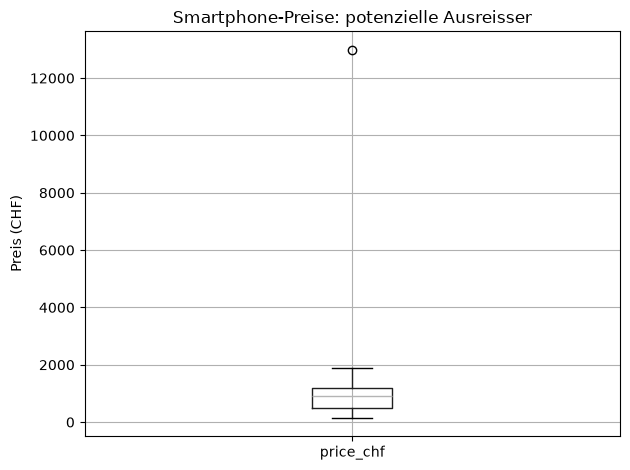

In [35]:
#Quartile der vorhandenen Originalpreise berechnen
outlier_q1 = df_dpspick_smartphone['price_chf'].quantile(0.25)                  #Unteres Quartil
outlier_q3 = df_dpspick_smartphone['price_chf'].quantile(0.75)                  #Oberes Quartil
outlier_iqr = outlier_q3 - outlier_q1                                           #Streuungsbreite der mittleren 50 Prozent

#Grenzen für potenzielle Ausreisser bestimmen
outlier_lower = outlier_q1 - 1.5 * outlier_iqr
outlier_upper = outlier_q3 + 1.5 * outlier_iqr
print('IQR:', outlier_iqr)
print('Untere Grenze:', outlier_lower)
print('Obere Grenze:', outlier_upper)

#Preise ausserhalb der Grenzen markieren
df_dpspick_smartphone['price_outlier'] = (
    (df_dpspick_smartphone['price_chf'] < outlier_lower)
    | (df_dpspick_smartphone['price_chf'] > outlier_upper)
).astype('boolean')                                                             #True = Auffällig; False = Innerhalb der Grenzen

#Fehlende Preise oder nicht berechenbare Grenzen als nicht beurteilbar markieren
df_dpspick_smartphone.loc[
    df_dpspick_smartphone['price_chf'].isna(),
    'price_outlier'
] = pd.NA

if pd.isna(outlier_iqr):
    df_dpspick_smartphone['price_outlier'] = pd.Series(
        pd.NA,
        index=df_dpspick_smartphone.index,
        dtype='boolean'
    )                                                                           #Keine gültigen Preise => Keine Beurteilung möglich

#Originalpreis und Markierung kontrollieren
display(
    df_dpspick_smartphone[['price_chf', 'price_outlier']].head()
)

#Anzahl potenzieller Ausreisser anzeigen
print(
    'Anzahl potenzieller Ausreisser:',
    df_dpspick_smartphone['price_outlier'].sum()
)                                                                               #Fehlende Markierungen werden beim Zählen ausgelassen

#Auffällige Smartphones gezielt untersuchen
display(
    df_dpspick_smartphone.loc[
        df_dpspick_smartphone['price_outlier'].fillna(False),
        ['product_id', 'brand', 'model', 'price_chf', 'price_outlier']
    ].head(10)
)

#Originalpreise als Boxplot darstellen
if df_dpspick_smartphone['price_chf'].notna().any():
    df_dpspick_smartphone.boxplot(column='price_chf')
    plt.ylabel('Preis (CHF)')
    plt.title('Smartphone-Preise: potenzielle Ausreisser')
    plt.tight_layout()
    plt.show()

#ANPASSEN: DataFrame, Ausgangsspalte price_chf und Zielspalte price_outlier
#ANPASSEN: Anzeigespalten und Diagrammbeschriftungen an die Aufgabe
#OPTIONAL: Faktor 1.5 ändern, falls die Aufgabe andere Grenzen vorgibt
#VORAUSSETZUNG: Numerische, endliche Originalpreise; pandas und matplotlib.pyplot als plt importiert
#HINWEIS: Originalspalte price_chf statt price_chf_imputed untersuchen
#ACHTUNG: Bei IQR = 0 die statistischen Markierungen kritisch prüfen
#ERKENNTNIS: Auffällige Werte werden markiert; keine Preise geändert oder Zeilen gelöscht

### Potenzielle Ausreisser gezielt ausschliessen

Nach fachlicher Prüfung kann für eine separate Analyse eine gefilterte Kopie erstellt werden. Die Originaldaten bleiben erhalten

- Der folgende Code schliesst alle als Ausreisser markierten Preise aus
- Fehlende Preise bleiben ausdrücklich erhalten: „fehlend“ bedeutet nicht „Ausreisser“
- Bestimmte Werte, Bereiche oder IDs lassen sich mit den bereits behandelten Filtern ausschliessen
- Ein statistisch auffälliger Wert darf nicht ohne fachliche Begründung entfernt werden

In [36]:
#Separate Analyse ohne die zuvor markierten IQR-Ausreisser vorbereiten
df_without_outliers = df_dpspick_smartphone.loc[
    ~df_dpspick_smartphone['price_outlier'].fillna(False)
].copy()                                                                        #Fehlende Markierungen als False behandeln: Diese Zeilen bleiben erhalten

#Zeilenanzahl vor und nach dem Ausschluss vergleichen
print('Original:', len(df_dpspick_smartphone))
print('Ohne markierte Ausreisser:', len(df_without_outliers))

#Gefilterte Daten kontrollieren
display(
    df_without_outliers[
        ['product_id', 'brand', 'price_chf', 'price_outlier']
    ].head()
)

#VORAUSSETZUNG: Vorherigen IQR-Block ausführen; price_outlier muss existieren
#ACHTUNG: Nur bei fachlich begründetem Ausschluss für die Analyse verwenden
#Originaldaten bleiben unverändert; weitere Beispiele verwenden weiterhin df_dpspick_smartphone

Original: 142
Ohne markierte Ausreisser: 141


,product_id,brand,price_chf,price_outlier
0,PM-10001,Xiaomi,299.0,False
1,PM-10002,OnePlus,899.0,False
2,PM-10003,Google,1249.0,False
3,PM-10004,Samsung,339.0,False
4,PM-10005,Samsung,NaN,<NA>


## Use string manipulation methods to create additional variables

#### Textwerte bereinigen und vereinheitlichen

| Befehl | Erklärung |
|---|---|
| `df['spalte'].str.lower()` | Alle Buchstaben in Kleinbuchstaben umwandeln, bspw. `"Schöne Wohnung"` → `"schöne wohnung"` |
| `df['spalte'].str.upper()` | Alle Buchstaben in Grossbuchstaben umwandeln, bspw. `"Schöne Wohnung"` → `"SCHÖNE WOHNUNG"` |
| `df['spalte'].str.strip()` | Leerraum am Anfang und Ende entfernen, bspw. `"  Schöne Wohnung  "` → `"Schöne Wohnung"` |
| `df['spalte'].str.replace('Wohnung', 'Apartment', regex=False)` | Einen wörtlichen Text ersetzen, bspw. `"Schöne Wohnung"` → `"Schöne Apartment"` |
| `df['spalte'].str.replace(r'\s+', ' ', regex=True).str.strip()` | Mehrere aufeinanderfolgende Leerraumzeichen durch ein Leerzeichen ersetzen und äusseren Leerraum entfernen, bspw. `"  Schöne   Wohnung  "` → `"Schöne Wohnung"` |
| `df['spalte'].replace(r'^\s*$', pd.NA, regex=True)` | Leere Texte oder Texte aus ausschliesslich Leerraum als fehlende Werte speichern, bspw. `""` oder `"   "` → `pd.NA` |
| `df['spalte'].str.capitalize()` | Ersten Buchstaben gross-, Rest kleinschreiben, bspw. `"SCHÖNE WOHNUNG"` → `"Schöne wohnung"`; Achtung: `"BMW"` wird zu `"Bmw"` |
| `df['spalte'].str.lstrip()` | Leerraum nur am Anfang entfernen |
| `df['spalte'].str.rstrip()` | Leerraum nur am Ende entfernen |
| `df['spalte'].str.split(' ', n=1)` | Am ersten Leerzeichen in höchstens zwei Teile aufteilen; Ergebnis pro Zeile ist eine Liste |
| `df['spalte'].str.count(r'\d')` | Einzelne Ziffern zählen, bspw. `"A5 245 PS"` → `4` |

**Wichtig:** `.str` ermöglicht Textmethoden auf einer ganzen Spalte. Bei einem einzelnen Text verwendet man bspw. `text.lower()`. `regex=False` behandelt den Suchtext wörtlich; `regex=True` interpretiert ihn als Regex-Muster. Erst durch eine Zuweisung wie `df['spalte'] = ...` wird das Ergebnis im DataFrame gespeichert

In [20]:
#Text einer Spalte in Kleinbuchstaben umwandeln
df_dpspick_apartments['description_raw'] = (
    df_dpspick_apartments['description_raw'].str.lower()
)                                                                               #"Schöne Wohnung" => "schöne wohnung"; ANPASSEN: DataFrame und Spalte

#Text einer Spalte in Grossbuchstaben umwandeln
df_dpspick_apartments['description_raw'] = (
    df_dpspick_apartments['description_raw'].str.upper()
)                                                                               #"Schöne Wohnung" => "SCHÖNE WOHNUNG"; ANPASSEN: DataFrame und Spalte

#Leerzeichen am Anfang und Ende entfernen
df_dpspick_apartments['description_raw'] = (
    df_dpspick_apartments['description_raw'].str.strip()
)                                                                               #"  Schöne Wohnung  " => "Schöne Wohnung"; ANPASSEN: DataFrame und Spalte

#Bestimmte Zeichen oder Texte ersetzen
df_dpspick_apartments['description_raw'] = (
    df_dpspick_apartments['description_raw'].str.replace('Wohnung', 'Apartment', regex=False)
)                                                                               #"Schöne Wohnung" => "Schöne Apartment"; ANPASSEN: Spalte, Suchtext und Ersatztext

#Mehrere aufeinanderfolgende Leerraumzeichen durch ein Leerzeichen ersetzen
df_dpspick_apartments['description_raw'] = (
    df_dpspick_apartments['description_raw'].str.replace(r'\s+', ' ', regex=True).str.strip()
)                                                                               #"  Schöne   Wohnung  " => "Schöne Wohnung"; ANPASSEN: DataFrame und Spalte

#Leere Texte und Texte aus ausschliesslich Leerraum als fehlende Werte speichern
df_dpspick_apartments['description_raw'] = (
    df_dpspick_apartments['description_raw'].replace(r'^\s*$', pd.NA, regex=True)
)                                                                               #"" oder "   " => fehlender Wert; ANPASSEN: DataFrame und Spalte

#Ersten Buchstaben gross-, restliche Buchstaben kleinschreiben
df_dpspick_apartments['description_raw'] = (
    df_dpspick_apartments['description_raw'].str.capitalize()
)                                                                               #"SCHÖNE WOHNUNG" => "Schöne wohnung"; ANPASSEN: DataFrame und Spalte

#Leerraum nur am Anfang entfernen
df_dpspick_apartments['description_raw'] = (
    df_dpspick_apartments['description_raw'].str.lstrip()
)                                                                               #"  Wohnung  " => "Wohnung  "; ANPASSEN: DataFrame und Spalte

#Leerraum nur am Ende entfernen
df_dpspick_apartments['description_raw'] = (
    df_dpspick_apartments['description_raw'].str.rstrip()
)                                                                               #"  Wohnung  " => "  Wohnung"; ANPASSEN: DataFrame und Spalte

#Fahrzeugbezeichnung am ersten Leerzeichen aufteilen
df_dpspick_autoscout['type_parts'] = (
    df_dpspick_autoscout['type'].str.split(' ', n=1)
)                                                                               #"AUDI A5 Sportback" => ["AUDI", "A5 Sportback"]; ANPASSEN: Trennzeichen und n

#Ausgangstext und Textteile kontrollieren
display(
    df_dpspick_autoscout[['type', 'type_parts']].head()
)

#Einzelne Ziffern in der Fahrzeugbezeichnung zählen
df_dpspick_autoscout['type_digit_count'] = (
    df_dpspick_autoscout['type'].str.count(r'\d')
)                                                                               #"A5 245 PS" => 4; ANPASSEN: Suchmuster und Zielspalte

#Ausgangstext und Ziffernanzahl kontrollieren
display(
    df_dpspick_autoscout[['type', 'type_digit_count']].head()
)

,type,type_parts
0,AUDI A5 Sportback 3.0 TDI quattro S-tronic (Li...,"[AUDI, A5 Sportback 3.0 TDI quattro S-tronic (..."
1,MERCEDES-BENZ SLK 200 7G-Tronic (Cabriolet),"[MERCEDES-BENZ, SLK 200 7G-Tronic (Cabriolet)]"
2,MERCEDES-BENZ C 350 Avantgarde 4Matic 7G-Troni...,"[MERCEDES-BENZ, C 350 Avantgarde 4Matic 7G-Tro..."
3,MERCEDES-BENZ A 45 AMG 4Matic Speedshift 7G-DC...,"[MERCEDES-BENZ, A 45 AMG 4Matic Speedshift 7G-..."
4,AUDI A5 Sportback 2.0 TFSI Sport quattro S-tro...,"[AUDI, A5 Sportback 2.0 TFSI Sport quattro S-t..."


,type,type_digit_count
0,AUDI A5 Sportback 3.0 TDI quattro S-tronic (Li...,3
1,MERCEDES-BENZ SLK 200 7G-Tronic (Cabriolet),4
2,MERCEDES-BENZ C 350 Avantgarde 4Matic 7G-Troni...,5
3,MERCEDES-BENZ A 45 AMG 4Matic Speedshift 7G-DC...,4
4,AUDI A5 Sportback 2.0 TFSI Sport quattro S-tro...,3


### Change strings in 'Spalte' and 'Spalte' to uppercase 

##### Textspalte in Grossbuchstaben umwandeln und optional Leerraum entfernen

Vereinheitlicht die Schreibweise einer Textspalte und speichert das Ergebnis in derselben Spalte

- Variante 1: Nur in Grossbuchstaben umwandeln
- Variante 2: Zusätzlich Leerraum am Anfang und Ende entfernen
- ANPASSEN: Spaltennamen; für weitere Textspalten den jeweiligen Block wiederholen
- Leerzeichen innerhalb des Textes bleiben erhalten

In [21]:
#Eine der beiden Varianten nehmen, 'type' überall auf Spaltennamen ändern
# Variante 1: Nur Grossbuchstaben
df_dpspick_autoscout['type'] = df_dpspick_autoscout['type'].str.upper()         #Texte in Grossbuchstaben umwandeln und zurückspeichern
                                                                                #.str: Textmethoden anwenden; upper(): Buchstaben grossschreiben
print(df_dpspick_autoscout['type'].head())                                      #Erste fünf Werte zur Kontrolle anzeigen

# Variante 2: Grossbuchstaben und äusseren Leerraum entfernen
df_dpspick_autoscout['type'] = df_dpspick_autoscout['type'].str.upper().str.strip()     
                                                                                #Schreibweise vereinheitlichen und äusseren Leerraum entfernen
                                                                                #upper(): Grossbuchstaben; strip(): Leerraum am Anfang und Ende entfernen
print(df_dpspick_autoscout['type'].head())                                      #Erste fünf Werte zur Kontrolle anzeigen

#ANPASSEN: Spalte, "model' bzw. 'brand' überall im jeweiligen Block an die gewünschte Spalte
#OPTIONAL: .str.lower() statt .str.upper() für Kleinbuchstaben

0    AUDI A5 SPORTBACK 3.0 TDI QUATTRO S-TRONIC (LI...
1          MERCEDES-BENZ SLK 200 7G-TRONIC (CABRIOLET)
2    MERCEDES-BENZ C 350 AVANTGARDE 4MATIC 7G-TRONI...
3    MERCEDES-BENZ A 45 AMG 4MATIC SPEEDSHIFT 7G-DC...
4    AUDI A5 SPORTBACK 2.0 TFSI SPORT QUATTRO S-TRO...
Name: type, dtype: str
0    AUDI A5 SPORTBACK 3.0 TDI QUATTRO S-TRONIC (LI...
1          MERCEDES-BENZ SLK 200 7G-TRONIC (CABRIOLET)
2    MERCEDES-BENZ C 350 AVANTGARDE 4MATIC 7G-TRONI...
3    MERCEDES-BENZ A 45 AMG 4MATIC SPEEDSHIFT 7G-DC...
4    AUDI A5 SPORTBACK 2.0 TFSI SPORT QUATTRO S-TRO...
Name: type, dtype: str


### Calculate length of strings in 'Spalte' and 'Spalte'

Textlängen berechnen und als Histogramm darstellen

Zählt für jeden Text die Zeichen inklusive Leerzeichen und Satzzeichen und speichert die Anzahl in einer neuen Spalte

Das Histogramm zeigt auf der x-Achse die Textlänge und auf der y-Achse die Anzahl Texte je Längenintervall

- Variante 1: Eine Textspalte mit Histogramm und geglätteter Verteilungskurve
- Variante 2: Mehrere Textspalten mit jeweils eigenem Histogramm
- ANPASSEN: Tabellenname, Ausgangsspalten und Namen der neuen Längenspalten
- apply(len) setzt voraus, dass jeder Wert eine Länge besitzt, bspw. ein Text ist
- .str.len() lässt fehlende Texte fehlend; Histogramme berücksichtigen diese fehlenden Werte nicht

,type,type_len
0,AUDI A5 SPORTBACK 3.0 TDI QUATTRO S-TRONIC (LI...,54
1,MERCEDES-BENZ SLK 200 7G-TRONIC (CABRIOLET),43
2,MERCEDES-BENZ C 350 AVANTGARDE 4MATIC 7G-TRONI...,59
3,MERCEDES-BENZ A 45 AMG 4MATIC SPEEDSHIFT 7G-DC...,59
4,AUDI A5 SPORTBACK 2.0 TFSI SPORT QUATTRO S-TRO...,61


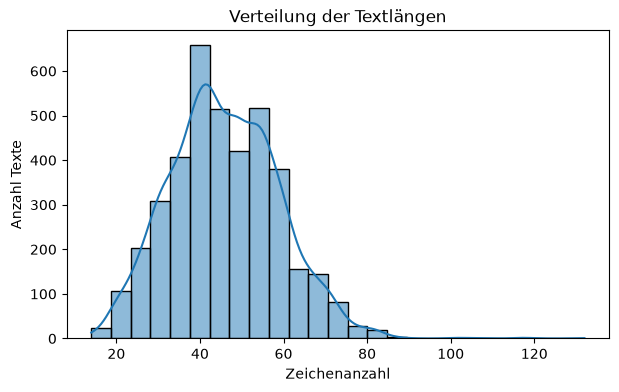

In [22]:
#Eine Spalte:
import matplotlib.pyplot as plt                                                 #Diagrammfunktionen laden
import seaborn as sns                                                           #Statistische Diagrammfunktionen laden

#.apply(len) wendet len() auf jeden einzelnen Wert der Spalte an und zählt dessen Zeichen, inkl. Leerzeichen und Satzzeichen
#bspw. "AUDI" → 4 "AUDI A5" → 7 "" → 0 Die Ergebnisse werden in type_len gespeichert
#Bei fehlenden Texten kann .apply(len) einen Fehler auslösen; .str.len() lässt diese Werte stattdessen fehlend
df_dpspick_autoscout['type_len'] = df_dpspick_autoscout['type'].apply(len)      #Zeichenanzahl in einer neuen Spalte speichern
                                                                                #apply(len): len() auf jeden Text anwenden
display(df_dpspick_autoscout[['type', 'type_len']].head())                      #Ausgangstext und Länge für die ersten fünf Zeilen anzeigen

plt.figure(figsize=(7, 4))                                                      #Neue Abbildung mit 7 × 4 Zoll erstellen
sns.histplot(df_dpspick_autoscout['type_len'], bins=25, kde=True)               #Histogramm mit 25 Intervallen zeichnen
                                                                                #kde=True: geglättete Verteilungskurve ergänzen
plt.title('Verteilung der Textlängen')                                          #Diagrammtitel setzen
plt.xlabel('Zeichenanzahl')                                                     #x-Achse beschriften
plt.ylabel('Anzahl Texte')                                                      #y-Achse beschriften
plt.show()                                                                      #Diagramm anzeigen

#ANPASSEN: df_autoscout überall an deinen Tabellennamen
#ANPASSEN: type an die vorhandene Textspalte; type_len an die neue Längenspalte
#OPTIONAL: bins, figsize und Beschriftungen ändern; kde=False für keine Kurve
#BEI FEHLENDEN TEXTEN: .str.len() statt .apply(len) verwenden

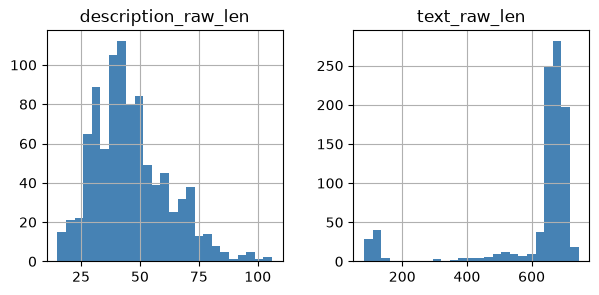

In [23]:
#Mehrere Spalten
import matplotlib.pyplot as plt                                                 #Diagrammfunktionen laden

df_dpspick_apartments['description_raw_len'] = df_dpspick_apartments['description_raw'].str.len()   #Beschreibungslängen speichern
df_dpspick_apartments['text_raw_len'] = df_dpspick_apartments['text_raw'].str.len()                 #Textlängen speichern
                                                                                #.str.len(): Zeichen zählen; fehlende Texte bleiben fehlend

ax = df_dpspick_apartments[['description_raw_len', 'text_raw_len']].hist(
    bins=25,                                                                    #Pro Längenspalte ein Histogramm mit 25 Intervallen erstellen
    figsize=(7, 3),                                                             #Gesamtgrösse der Abbildung in Zoll
    color='steelblue'                                                           #Balkenfarbe festlegen
)

for axis in ax.flatten():                                                       #Achsenanordnung abflachen und jede Diagrammachse durchlaufen
    axis.set_ylim(bottom=0)                                                     #y-Achse bei 0 beginnen lassen; obere Grenze automatisch bestimmen

plt.show()                                                                      #Histogramme anzeigen

#ANPASSEN: description_raw und text_raw an die vorhandenen Textspalten
#ANPASSEN: description_raw_len und text_raw_len überall an die neuen Längenspalten
#OPTIONAL: bins, figsize und color ändern
#BEI VORGEGEBENER Y-GRENZE: z. B. axis.set_ylim(0, 300) verwenden

## Neue Variablen erstellen und berechnen

### Binäre Variablen aus Textsuche oder Bedingungen erstellen

Prüft jede Zeile auf Suchbegriffe oder numerische Bedingungen und speichert `1` bei erfüllter Bedingung, sonst `0`

| Befehl | Erklärung |
|---|---|
| `df['text'].str.contains('RENOVIERT\|SANIERT\|NEUBAU', case=False, na=False).astype(int)` | Mind. einen Suchbegriff finden; Gross-/Kleinschreibung ignorieren; fehlender Text ergibt `0` |
| `(df['price'] > 1000).astype(int)` | Preis über 1000 als `1`, sonst als `0` markieren |
| `((df['price'] > 1000) & (df['brand'] == 'Samsung')).astype(int)` | Samsung mit einem Preis über 1000 als `1` markieren |
| `(df['price'].astype('Float64') > 1000).astype('Int64')` | Preisbedingung prüfen und fehlende Preise als `<NA>` erhalten |
| `df['match'].sum()` | Einsen addieren und damit passende Zeilen zählen |
| `df.loc[df['match'] == 1]` | Nur passende Zeilen anzeigen |

**Wichtig:**
- Ergebnis mit `df['match'] = ...` als neue Spalte speichern
- Suchbegriffe mit `|` verbinden; dies bedeutet ODER. Auch Wortteile werden gefunden
- Bedingungen einzeln einklammern und mit `&` (UND) oder `|` (ODER) verbinden
- Fehlende Werte bewusst behandeln: Bei gewöhnlichem `float64` ergibt ein Vergleich wie `NaN > 1000` den Wert `False`

In [24]:
#Suchbegriffe festlegen und mit ODER verbinden
pattern = 'RENOVIERT|SANIERT|NEUBAU'                                            #ANPASSEN: Suchbegriffe; ein passender Begriff genügt

#Text durchsuchen und Treffer als 1, sonst als 0 speichern
df_dpspick_apartments['match'] = (
    df_dpspick_apartments['description_raw']
        .str.contains(pat=pattern, case=False, na=False)
        .astype(int)
)                                                                               #"Frisch saniert" => 1; kein Treffer oder fehlender Text => 0

#Treffer zählen und passende Zeilen anzeigen
print("Anzahl Treffer:", df_dpspick_apartments['match'].sum())
display(
    df_dpspick_apartments.loc[
        df_dpspick_apartments['match'] == 1,
        ['description_raw', 'match']
    ]
)                                                                               #ANPASSEN: DataFrame, Ausgangsspalte und Zielspalte


#Preis über 1000 CHF als 1 markieren und fehlende Preise erhalten
df_dpspick_smartphone['price_over_1000'] = (
    df_dpspick_smartphone['price_chf'].astype('Float64') > 1000
).astype('Int64')                                                               #1249 => 1; 849 => 0; fehlend => <NA>; ANPASSEN: Spalten und Grenzwert

#Ausgangswert und neue Markierung anzeigen
display(df_dpspick_smartphone[['price_chf', 'price_over_1000']].head())


#Samsung UND Preis über 1000 CHF als 1 markieren
df_dpspick_smartphone['samsung_over_1000'] = (
    (df_dpspick_smartphone['brand'].astype('string') == 'Samsung') &
    (df_dpspick_smartphone['price_chf'].astype('Float64') > 1000)
).astype('Int64')                                                               #Samsung mit 1249 CHF => 1; ANPASSEN: Marke, Grenzwert und Spalten

#Bei fehlender Marke oder fehlendem Preis auch die Markierung fehlend setzen
df_dpspick_smartphone.loc[
    df_dpspick_smartphone[['brand', 'price_chf']].isna().any(axis=1),
    'samsung_over_1000'
] = pd.NA                                                                       #Mindestens ein Ausgangswert fehlt => <NA>

#Ausgangswerte und neue Markierung anzeigen
display(
    df_dpspick_smartphone[['brand', 'price_chf', 'samsung_over_1000']].head()
)

Anzahl Treffer: 67


,description_raw,match
5,«moderne 3.5-zimmer-neubauwohnung mit balkon u...,1
32,«neubau - wohlfühlfeeling garantiert»,1
35,"«viel raum, renoviert und zentral»",1
48,«grosszügige neubauwohnung im obersten geschoss»,1
68,«attraktive attika-neubauwohnung in pfungen»,1
...,...,...
878,«neu renovierte 3.5 zimmer wohnung»,1
890,«umfassend sanierte duplex dachwohnung»,1
904,«3.5 zimmerwohnung neubau»,1
905,«2.5 zimmerwohnung neubau»,1


,price_chf,price_over_1000
0,299.0,0
1,899.0,0
2,1249.0,1
3,339.0,0
4,NaN,<NA>


,brand,price_chf,samsung_over_1000
0,Xiaomi,299.0,0
1,OnePlus,899.0,0
2,Google,1249.0,0
3,Samsung,339.0,0
4,Samsung,NaN,<NA>


### Create binary (0/1) Variable
Text nach Suchbegriffen durchsuchen, als 0/1 markieren und Treffer zählen

Prüft jede Zeile auf mind. einen Suchbegriff und speichert eine 1 bei einem Treffer, sonst eine 0. Anschliessend werden die Treffer gezählt und angezeigt

- Suchbegriffe mit | verbinden, das bedeutet ODER. Diesen String der Variable pattern zuweisen
- Ausgangsspalte: vorhandene Textspalte, die durchsucht wird
- Zielspalte: neue Spalte für die 0/1-Markierung
- Die Suche beachtet Gross-/Kleinschreibung. Für eine Suche unabhängig davon case=False ergänzen
- Es werden auch Wortteile gefunden

In [25]:
# Create a search pattern
pattern = 'RENOVIERT|SANIERT|NEUBAU'                                            #Suchbegriffe festlegen; | bedeutet ODER – ein passender Begriff genügt

# Create a binary (0/1) variable
df_dpspick_apartments['Neuer Spaltennamen'] = df_dpspick_apartments['description_raw'].str.contains(pat=pattern, na=False).astype(int)   
                                                                                #Text jeder Zeile prüfen und Ergebnis in match speichern
                                                                                #str.contains(): gesuchter Begriff enthalten → True, sonst False
                                                                                #astype(int): True → 1, False → 0; na=False: fehlender Text → kein Treffer
# Count matching rows
print("Anzahl Treffer:", df_dpspick_apartments['Neuer Spaltennamen'].sum())     #Einsen addieren: Jede passende Zeile zählt einmal

# Show matching rows
df_dpspick_apartments[['description_raw', 'Neuer Spaltennamen']].loc[df_dpspick_apartments['Neuer Spaltennamen'] == 1]         
                                                                                #Ausgangstext und Markierung nur für Treffer anzeigen
                                                                                #[[...]]: Spalten auswählen; .loc[...]: Zeilen mit match == 1 behalten

#ANPASSEN: Suchbegriffe in pattern
#ANPASSEN: description_raw an deine Spalte (die alte Spalte!)
#ANPASSEN: Neuer Spaltenname an den gewünschten Zielspaltennamen
#OPTIONAL: Weitere Spalten in der Anzeige ergänzen, bspw. df[['description_raw', 'rooms', 'area', 'price', 'match']].loc[df['match'] == 1]
#OPTIONAL: Gross-/Kleinschreibung ignorieren → str.contains(pat=pattern, case=False, na=False)

Anzahl Treffer: 0


,description_raw,Neuer Spaltennamen


### Numerische Variablen aus vorhandenen Spalten berechnen

Verrechnet vorhandene Zahlenspalten und speichert das Ergebnis in einer neuen Spalte

| Befehl | Erklärung |
|---|---|
| `df['price_per_hp'] = (df['price'] / df['hp']).round(2)` | Preis pro PS berechnen und auf zwei Nachkommastellen runden |
| `df['price_per_hp'] = (df['price'] / df['hp'].replace(0, float('nan'))).round(2)` | Division durch 0 verhindern; bei 0 PS wird das Ergebnis fehlend |
| `df['total'] = df['quantity'] * df['unit_price']` | Menge mit Einzelpreis multiplizieren |
| `df['total'] = df['price'] + df['fees']` | Preis und Gebühren addieren |
| `df['difference'] = df['income'] - df['expenses']` | Differenz zwischen zwei Zahlenspalten berechnen |

**Wichtig:**
- Beide Ausgangsspalten müssen numerisch sein
- Rechenzeichen: `/` Division, `*` Multiplikation, `+` Addition, `-` Subtraktion
- Fehlende Ausgangswerte ergeben bei diesen Berechnungen einen fehlenden Ergebniswert
- Die Ersetzung von 0 innerhalb der Berechnung verändert die ursprüngliche PS-Spalte nicht
- Ausgangsspalten, Zielspalte und Anzahl Nachkommastellen anpassen

In [26]:
#Preistext für die Berechnung in Zahlen umwandeln
price = pd.to_numeric(
    df_dpspick_autoscout['price_raw']
        .str.replace('CHF', '', regex=False)
        .str.replace("'", '', regex=False)
        .str.replace('’', '', regex=False)
        .str.replace(r'\.[—–-]', '', regex=True)
        .str.strip(),
    errors='coerce'
)                                                                               #"CHF 22'500.–" => 22500; ANPASSEN: DataFrame und Rohtextspalte

#PS-Text für die Berechnung in Zahlen umwandeln
hp = pd.to_numeric(
    df_dpspick_autoscout['hp_raw']
        .str.replace('PS', '', regex=False)
        .str.strip(),
    errors='coerce'
)                                                                               #"245 PS" => 245; ANPASSEN: DataFrame und Rohtextspalte

#Preis pro PS berechnen und Division durch 0 verhindern
df_dpspick_autoscout['price_per_hp'] = (
    price / hp.replace(0, float('nan'))
).round(2)                                                                      #22500 / 245 => 91.84; ANPASSEN: Zielspalte und Rundung

#Ausgangswerte und berechneten Wert anzeigen
display(
    df_dpspick_autoscout[['price_raw', 'hp_raw', 'price_per_hp']].head()
)


#Smartphone-Preis inklusive 8.1 Prozent Zuschlag berechnen
df_dpspick_smartphone['price_with_surcharge'] = (
    df_dpspick_smartphone['price_chf'] * 1.081
).round(2)                                                                      #1000 × 1.081 => 1081.0; ANPASSEN: Ausgangsspalte, Zielspalte und Faktor

#Ausgangswert und berechneten Wert anzeigen
display(df_dpspick_smartphone[['price_chf', 'price_with_surcharge']].head())


#Zum Smartphone-Preis einen festen Betrag addieren
df_dpspick_smartphone['price_with_shipping'] = (
    df_dpspick_smartphone['price_chf'] + 10
).round(2)                                                                      #1000 + 10 => 1010.0; ANPASSEN: Ausgangsspalte, Zielspalte und Zuschlag

#Ausgangswert und berechneten Wert anzeigen
display(df_dpspick_smartphone[['price_chf', 'price_with_shipping']].head())


#Vom Smartphone-Preis einen festen Betrag abziehen
df_dpspick_smartphone['price_discounted'] = (
    df_dpspick_smartphone['price_chf'] - 50
).round(2)                                                                      #1000 − 50 => 950.0; ANPASSEN: Ausgangsspalte, Zielspalte und Rabatt

#Ausgangswert und berechneten Wert anzeigen
display(df_dpspick_smartphone[['price_chf', 'price_discounted']].head())

,price_raw,hp_raw,price_per_hp
0,CHF 22'500.–,245 PS,91.84
1,CHF 23'749.–,184 PS,129.07
2,CHF 18'500.–,306 PS,60.46
3,CHF 36'000.–,360 PS,100.00
4,CHF 48'500.–,252 PS,192.46


,price_chf,price_with_surcharge
0,299.0,323.22
1,899.0,971.82
2,1249.0,1350.17
3,339.0,366.46
4,NaN,NaN


,price_chf,price_with_shipping
0,299.0,309.0
1,899.0,909.0
2,1249.0,1259.0
3,339.0,349.0
4,NaN,NaN


,price_chf,price_discounted
0,299.0,249.0
1,899.0,849.0
2,1249.0,1199.0
3,339.0,289.0
4,NaN,NaN


### Create Variable
Neue Spalte berechnen: Zwei Zahlenspalten verrechnen und Ergebnis runden

Berechnet für jede Zeile einen neuen Wert aus zwei vorhandenen Zahlenspalten und speichert ihn in einer zusätzlichen Spalte

Bsp.: Preis durch PS-Zahl teilen → Preis pro PS

- ANPASSEN: Ausgangsspalten, Zielspalte und Anzahl Nachkommastellen
- Rechenzeichen: / Division, * Multiplikation, + Addition, - Subtraktion
- Beide Ausgangsspalten müssen numerisch sein; bei einer Division darf der Nenner nicht 0 sein
- Fehlende Ausgangswerte ergeben einen fehlenden Ergebniswert

#### Einschub: Voraussetzung - Numerische Spalten vor der Berechnung erstellen

Für den Preis pro PS müssen die Spalten `price` und `hp` bereits als Zahlen in derselben Tabelle vorhanden sein
Die Rohdaten enthalten zunächst nur `Price_Raw` und `HP_Raw` mit Texten wie `"CHF 22'500.–"` und `"245 PS"`

1. Spaltennamen kleinschreiben: `df_autoscout.columns = df_autoscout.columns.str.lower()` macht bspw. aus `Price_Raw` den Namen `price_raw`; die Inhalte bleiben unverändert

2. Preis- und PS-Regex-Bausteine ausführen: Diese extrahieren die Zahlen aus `price_raw` und `hp_raw` und speichern sie als neue numerische Spalten `price` und `hp`

3. In beiden Bausteinen überall `df_autoscout` statt `df` verwenden, damit die neuen Spalten in der richtigen Tabelle entstehen

4. Anschliessend den Preis durch die PS-Zahl teilen: `df_autoscout['price_per_hp'] = round(df_autoscout['price'] / df_autoscout['hp'], 2)`

ANPASSEN: Tabellenname und Spaltennamen an deine Aufgabe
Die Kleinschreibung der Spaltennamen allein wandelt keine Texte in Zahlen um

In [27]:
import re                                                                       #Regex-Funktionen laden
import pandas as pd                                                             #pandas für Tabellen laden

df_dpspick_autoscout.columns = df_dpspick_autoscout.columns.str.lower()         #Spaltennamen kleinschreiben: Price_Raw → price_raw

# Numerische Preisspalte erstellen
price = []                                                                      #Leere Liste für die Preise erstellen
for i in df_dpspick_autoscout['price_raw']:                                     #Jeden Preistext durchlaufen
    d1 = re.findall(r"CHF\s*([\d'’]+)\.[—–-]", i)                               #Betrag zwischen CHF und Preisendung erfassen
    try:
        d2 = d1[0].strip().replace("'", "").replace("’", "")                    #Ersten Treffer nehmen und Tausenderapostrophe entfernen
    except IndexError:                                                          #Kein passender Preis gefunden
        d2 = None                                                               #Fehlenden Wert verwenden
    price.append(d2)                                                            #Ergebnis zur Liste hinzufügen

df_dpspick_autoscout['price'] = pd.Series(price, index=df_dpspick_autoscout.index, dtype="Int64") #Neue numerische Preisspalte speichern; fehlende Werte erlauben

# Numerische PS-Spalte erstellen
hp = []                                                                         #Leere Liste für die PS-Werte erstellen
for i in df_dpspick_autoscout['hp_raw']:                                        #Jede PS-Angabe durchlaufen
    d1 = re.findall(r"\d+", i)                                                  #Ziffernfolgen finden; "245 PS" → ["245"]
    try:
        d2 = int(''.join(d1))                                                   #Ziffernfolgen verbinden und in eine ganze Zahl umwandeln
    except ValueError:                                                          #Keine umwandelbare Zahl gefunden
        d2 = None                                                               #Fehlenden Wert verwenden
    hp.append(d2)                                                               #Ergebnis zur Liste hinzufügen

df_dpspick_autoscout['hp'] = pd.Series(hp, index=df_dpspick_autoscout.index, dtype="Int64")     #Neue numerische PS-Spalte speichern; fehlende Werte erlauben

# Umwandlung kontrollieren
display(df_dpspick_autoscout[['price_raw', 'price', 'hp_raw', 'hp']].head())    #Rohtexte und extrahierte Zahlen vergleichen
print(df_dpspick_autoscout[['price', 'hp']].dtypes)                             #Prüfen, ob beide neuen Spalten numerisch sind

,price_raw,price,hp_raw,hp
0,CHF 22'500.–,22500,245 PS,245
1,CHF 23'749.–,23749,184 PS,184
2,CHF 18'500.–,18500,306 PS,306
3,CHF 36'000.–,36000,360 PS,360
4,CHF 48'500.–,48500,252 PS,252


price    Int64
hp       Int64
dtype: object


In [28]:
# Create the new variable
df_dpspick_autoscout['price_per_hp'] = round(df_dpspick_autoscout['price'] / df_dpspick_autoscout['hp'], 2)   
                                                                                #Preis durch PS-Zahl teilen und Ergebnis als neue Spalte speichern
                                                                                #round(..., 2): auf zwei Nachkommastellen runden

# Show values
df_dpspick_autoscout[['price', 'hp', 'price_per_hp']].head()                    #Ausgangswerte und Ergebnis für die ersten fünf Zeilen anzeigen
                                                                                #[[...]]: Spalten auswählen; head(): erste fünf Zeilen

#ANPASSEN: 'price' und 'hp' an die vorhandenen Zahlenspalten, in Berechnung und Anzeige
#ANPASSEN: 'price_per_hp' an den gewünschten neuen Spaltennamen, links vom = und in der Anzeige
#ANPASSEN: / an die Rechenoperation; 2 an die Anzahl Nachkommastellen
#OPTIONAL: .head() weglassen, um alle Zeilen anzufordern; weitere Anzeigespalten in [[...]] ergänzen

,price,hp,price_per_hp
0,22500,245,91.84
1,23749,184,129.07
2,18500,306,60.46
3,36000,360,100.0
4,48500,252,192.46


### Kategorien anhand von Bedingungen erstellen

Weist jeder Zeile abhängig von einer Bedingung eine Kategorie zu

| Befehl | Erklärung |
|---|---|
| `df['price_category'] = np.where(df['price'] > 1000, 'teuer', 'günstig')` | Preise über 1000 als „teuer“, übrige als „günstig“ einstufen |
| `df['price_category'] = df['price_category'].astype('string')` | Kategorien als Textspalte mit Unterstützung fehlender Werte speichern |
| `df.loc[df['price'].isna(), 'price_category'] = pd.NA` | Bei fehlendem Preis auch die Kategorie auf fehlend setzen |
| `df['price_category'].value_counts()` | Anzahl Datensätze je Kategorie zählen |

**Wichtig:** `import numpy as np` verwenden. Das einfache `np.where()`-Beispiel setzt voraus, dass die Bedingung keine `<NA>`-Werte enthält. Bei gewöhnlichem `float64` würde ein fehlender Preis zunächst als „günstig“ eingestuft; deshalb fehlende Preise anschliessend gesondert behandeln

In [29]:
#Preise über 1000 CHF als teuer, übrige Preise als günstig einstufen
df_dpspick_smartphone['price_category'] = pd.Series(
    np.where(
        df_dpspick_smartphone['price_chf'].gt(1000).fillna(False),
        'teuer',
        'günstig'
    ),
    index=df_dpspick_smartphone.index,
    dtype='string'
)                                                                               #1249 => "teuer"; 849 => "günstig"; ANPASSEN: Grenzwert und Kategorien

#Bei fehlendem Preis auch die Kategorie auf fehlend setzen
df_dpspick_smartphone.loc[
    df_dpspick_smartphone['price_chf'].isna(),
    'price_category'
] = pd.NA                                                                       #Fehlender Preis => fehlende Kategorie statt "günstig"

#Ausgangswert und zugewiesene Kategorie anzeigen
display(df_dpspick_smartphone[['price_chf', 'price_category']].head())

#Anzahl Smartphones je Kategorie einschliesslich fehlender Kategorie zählen
display(
    df_dpspick_smartphone['price_category'].value_counts(dropna=False)
)                                                                               #dropna=False: Fehlende Werte ebenfalls mitzählen

,price_chf,price_category
0,299.0,günstig
1,899.0,günstig
2,1249.0,teuer
3,339.0,günstig
4,NaN,<NA>


price_category
günstig    78
teuer      56
<NA>        8
Name: count, dtype: Int64

### Zeitstempel ergänzen

Speichert den Zeitpunkt der Ausführung in einer neuen Spalte. Alle Zeilen erhalten denselben Zeitstempel

| Befehl | Erklärung |
|---|---|
| `df['timestamp'] = datetime.now().strftime('%Y-%m-%d %H:%M:%S')` | Aktuellen Zeitpunkt als Text speichern; benötigt `from datetime import datetime` |
| `df['timestamp'] = pd.Timestamp.now()` | Aktuellen Zeitpunkt als echten Datumswert in der Systemzeitzone speichern |
| `df['timestamp'] = pd.Timestamp.now(tz='Europe/Zurich')` | Aktuellen Zeitpunkt als echten Datumswert mit Schweizer Zeitzone speichern |

**Wichtig:**
- Ein echter Datumsdatentyp ermöglicht Datumsvergleiche und Zeitdifferenzen; `strftime()` erzeugt Text
- Ohne Zeitzonenangabe wird die Systemzeit verwendet; diese kann in Codespaces von der Schweizer Zeit abweichen
- Erneutes Ausführen überschreibt den bisherigen Zeitstempel
- Formatzeichen: `%Y` Jahr, `%m` Monat, `%d` Tag, `%H` Stunde, `%M` Minute, `%S` Sekunde

In [30]:
#Aktuellen Zeitpunkt als Text speichern
df_dpspick_apartments['timestamp_text'] = (
    datetime.now().strftime('%Y-%m-%d %H:%M:%S')
)                                                                               #Bsp.: "2026-10-30 14:30:00"; ANPASSEN: Zielspalte und Textformat

#Zeitstempel als Text anzeigen
display(df_dpspick_apartments[['timestamp_text']].head())


#Aktuellen Zeitpunkt als echten Datumswert in der Systemzeitzone speichern
df_dpspick_apartments['timestamp_system'] = pd.Timestamp.now()                  #ANPASSEN: Zielspalte; Systemzeit kann von Schweizer Zeit abweichen

#Zeitstempel als Datumswert anzeigen
display(df_dpspick_apartments[['timestamp_system']].head())


#Aktuellen Zeitpunkt als echten Datumswert mit Schweizer Zeitzone speichern
df_dpspick_apartments['timestamp_zurich'] = pd.Timestamp.now(
    tz='Europe/Zurich'
)                                                                               #ANPASSEN: DataFrame, Zielspalte und Zeitzone

#Zeitstempel und Datentypen vergleichen
display(
    df_dpspick_apartments[
        ['timestamp_text', 'timestamp_system', 'timestamp_zurich']
    ].head()
)
display(
    df_dpspick_apartments[
        ['timestamp_text', 'timestamp_system', 'timestamp_zurich']
    ].dtypes
)

,timestamp_text
0,2026-10-31 02:07:38
1,2026-10-31 02:07:38
2,2026-10-31 02:07:38
3,2026-10-31 02:07:38
4,2026-10-31 02:07:38


,timestamp_system
0,2026-10-31 02:07:38.706071
1,2026-10-31 02:07:38.706071
2,2026-10-31 02:07:38.706071
3,2026-10-31 02:07:38.706071
4,2026-10-31 02:07:38.706071


,timestamp_text,timestamp_system,timestamp_zurich
0,2026-10-31 02:07:38,2026-10-31 02:07:38.706071,2026-10-31 03:07:38.713817+01:00
1,2026-10-31 02:07:38,2026-10-31 02:07:38.706071,2026-10-31 03:07:38.713817+01:00
2,2026-10-31 02:07:38,2026-10-31 02:07:38.706071,2026-10-31 03:07:38.713817+01:00
3,2026-10-31 02:07:38,2026-10-31 02:07:38.706071,2026-10-31 03:07:38.713817+01:00
4,2026-10-31 02:07:38,2026-10-31 02:07:38.706071,2026-10-31 03:07:38.713817+01:00


timestamp_text                                str
timestamp_system                   datetime64[us]
timestamp_zurich    datetime64[us, Europe/Zurich]
dtype: object

### Include current datetime as time stamp
Aktuelles Datum und Uhrzeit als Zeitstempel speichern

Speichert den Zeitpunkt der Ausführung als Text in einer neuen Spalte. Alle Zeilen erhalten denselben Zeitstempel

Bsp.: „2026-10-16 01:03:53“ dokumentiert, wann der Code ausgeführt wurde
Bei erneutem Ausführen wird der bisherige Zeitstempel überschrieben

- ANPASSEN: Tabellenname, Zielspaltenname und bei Bedarf Datumsformat
- %Y: vierstelliges Jahr; %m: Monat; %d: Tag
- %H: Stunde; %M: Minute; %S: Sekunde

In [31]:
from datetime import datetime                                                   #Werkzeug für Datum und Uhrzeit laden

df_dpspick_apartments['timestamp'] = datetime.now().strftime('%Y-%m-%d %H:%M:%S')       #Aktuellen Zeitpunkt als Text in jeder Zeile speichern
                                                                                #now(): aktueller Zeitpunkt; strftime(): gewünschtes Textformat erzeugen
df_dpspick_apartments['timestamp'].head()                                       #Zeitstempel der ersten fünf Zeilen anzeigen

#ANPASSEN: timestamp an den gewünschten neuen Spaltennamen, an beiden Stellen
#OPTIONAL: '%Y-%m-%d' für nur Datum oder '%d.%m.%Y %H:%M' für Tag.Monat.Jahr Stunde:Minute
#NICHTS ANPASSEN: übriger Code für einen Zeitstempel als Text

0    2026-10-31 02:07:38
1    2026-10-31 02:07:38
2    2026-10-31 02:07:38
3    2026-10-31 02:07:38
4    2026-10-31 02:07:38
Name: timestamp, dtype: str

### Datumstexte umwandeln und Datumsvariablen ableiten

Wandelt vorhandene Datumstexte in Datumswerte um und erstellt daraus beispielsweise Jahr, Monat oder Wochentag

| Befehl | Erklärung |
|---|---|
| `df['date'] = pd.to_datetime(df['date_raw'], format='%d.%m.%Y', errors='coerce')` | Datumstext umwandeln, bspw. `"30.10.2026"` → `2026-10-30`; ungültige Werte werden `NaT` |
| `df['year'] = df['date'].dt.year.astype('Int64')` | Jahr extrahieren; fehlende Werte bleiben `<NA>` |
| `df['month'] = df['date'].dt.month.astype('Int64')` | Monat als Zahl von 1 bis 12 extrahieren |
| `df['day'] = df['date'].dt.day.astype('Int64')` | Tag des Monats extrahieren |
| `df['weekday'] = df['date'].dt.dayofweek.astype('Int64')` | Wochentag extrahieren; Montag = 0, Sonntag = 6 |
| `df[df['date'].isna()]` | Zeilen mit fehlenden oder nicht konvertierbaren Datumswerten anzeigen |

**Wichtig:** Das Datumsformat muss zu den Ausgangstexten passen. `.dt` ermöglicht Datumsoperationen auf einer ganzen Spalte

In [32]:
#Beispieldaten mit Datumstexten erstellen
df_dates = pd.DataFrame({
    'date_raw': ['30.10.2026', '01.11.2026', 'keine Angabe']
})                                                                              #ANPASSEN: Bei echten Daten den bereits eingelesenen DataFrame verwenden

#Datumstexte in echte Datumswerte umwandeln
df_dates['date'] = pd.to_datetime(
    df_dates['date_raw'],
    format='%d.%m.%Y',
    errors='coerce'
)                                                                               #"30.10.2026" => 2026-10-30; ungültiger Text => NaT; ANPASSEN: Spalten und Format

#Jahr extrahieren und als Ganzzahl mit Unterstützung fehlender Werte speichern
df_dates['year'] = df_dates['date'].dt.year.astype('Int64')                     #2026-10-30 => 2026; ANPASSEN: Ausgangsspalte und Zielspalte

#Monat extrahieren
df_dates['month'] = df_dates['date'].dt.month.astype('Int64')                   #2026-10-30 => 10; ANPASSEN: Ausgangsspalte und Zielspalte

#Tag des Monats extrahieren
df_dates['day'] = df_dates['date'].dt.day.astype('Int64')                       #2026-10-30 => 30; ANPASSEN: Ausgangsspalte und Zielspalte

#Wochentag extrahieren
df_dates['weekday'] = df_dates['date'].dt.dayofweek.astype('Int64')             #Freitag => 4; Montag = 0, Sonntag = 6

#Rohtext, Datum und abgeleitete Werte anzeigen
display(df_dates[['date_raw', 'date', 'year', 'month', 'day', 'weekday']].head())

#Zeilen mit fehlendem oder nicht konvertierbarem Datum anzeigen
display(df_dates[df_dates['date'].isna()])                                      #"keine Angabe" => Zeile mit NaT

,date_raw,date,year,month,day,weekday
0,30.10.2026,2026-10-30,2026,10,30,4
1,01.11.2026,2026-11-01,2026,11,1,6
2,keine Angabe,NaT,<NA>,<NA>,<NA>,<NA>


,date_raw,date,year,month,day,weekday
2,keine Angabe,NaT,<NA>,<NA>,<NA>,<NA>
